Notebook for checking activations of finded expert's clusters. How they are similar of distinct?

In [1]:
import matplotlib.pyplot as plt
import numpy as np 
import os 
from pathlib import Path 
import torch 
from typing import *
import seaborn as sns
from sklearn.metrics import pairwise_distances
import ast
import pandas as pd
from sklearn.decomposition import PCA 
from sklearn.manifold import TSNE, Isomap, MDS

In [2]:
class ActivationParser:
    def __init__(self, root: Path, layer_prefix: str, task_mapping: dict = None):
        self.root = root if isinstance(root, Path) else Path(root)
        self.layer_prefix = layer_prefix
        self.task_mapping = task_mapping or {}
        self.task_to_idx = {v: k for k, v in self.task_mapping.items()}
        self.expert_infix = 'mlp.experts'
        self.gate_infix = 'mlp.gate'
        self.expert_to_idx_num = {task: {} for task in self.task_mapping}
      
    def parse_experts(self, layer: int, task='', as_gen=False):
        gen = self._parse_kind(layer, task)
        if as_gen:
            return gen 
        return dict(gen)
    
    def parse_gate(self, layer: int, task=''):
        # return next(iter(self._parse_kind(layer, task, self.gate_infix)))[1]
        path: Path = f'{self.root}/{self.layer_prefix}.{layer}.{self.gate_infix}'
        task = self.task_to_idx.get(task, 0) #TODO NOTE была ошибка с task_mapping вместо task_to_idx
        # print("TASK in parse gate!", task)
        # for expert in self.root.iterdir():
        #     if not expert.name.endswith(self.gate_infix):
        #         continue
        file = path + "/" + f'{task}.pth'
        t = torch.load(file, map_location='cuda:0').cpu()
        return t
        raise Exception('no gate found')

    def _parse_kind(self, layer, task):
        path: Path = f'{self.layer_prefix}.{layer}.{self.expert_infix}'
        task = self.task_to_idx[task]
        for expert in self.root.iterdir():
            if not str(path) in expert.name:
                continue
            n = int(expert.name.split('.')[-1])
            file = expert /  f'{task}.pth'
            if file.exists():
                t = torch.load(file, map_location='cuda:0').cpu()
                self.expert_to_idx_num[task][n] = t.size(0)
                yield n, t

    def get_experts_per_token(self, gate_output, k=4):
        return torch.topk(gate_output, k, dim=-1).indices
    
    def count_expert_calls(self, experts: Dict[int, torch.Tensor]):
        return {expert: value.size(0) for expert, value in experts.items()}
  
    def get_token_routing_map(self, layer: int, task: str = '', k: int = 4):
        """
        Returns a list of length = num_tokens.
        For each token i:
            token_routing[i] = list of tuples: (expert_id, row_idx_in_expert_tensor, gate_weight)
        
        gate_weight = softmax of the top-k logits for that token-expert pair
        (standard Mixtral / DeepSeek / most modern MoE routing)
        """
        gate_output = self.parse_gate(layer, task)          # (num_tokens, num_experts)
        n_tokens = gate_output.shape[0]
        num_experts = gate_output.shape[1]

        # 1. Get top-k experts + raw scores
        topk_values, topk_indices = torch.topk(gate_output, k, dim=-1)   # both (n_tokens, k)

        # 2. Convert raw top-k scores → actual routing weights (softmax per token)
        routing_weights = torch.softmax(topk_values, dim=-1)             # (n_tokens, k)

        # 3. Build per-expert list of tokens that were routed to it
        expert_to_tokens = [[] for _ in range(num_experts)]
        for t in range(n_tokens):
            for i in range(k):
                e = topk_indices[t, i].item()
                expert_to_tokens[e].append(t)

        # 4. For each expert, sort tokens by original index (this matches how activations are saved)
        expert_to_sorted_tokens = [sorted(tok_list) for tok_list in expert_to_tokens]

        # 5. Fast lookup: token → row index inside that expert's tensor
        expert_to_token2row = []
        for e in range(num_experts):
            token2row = {token: row_idx for row_idx, token in enumerate(expert_to_sorted_tokens[e])}
            expert_to_token2row.append(token2row)

        # 6. Build final map
        token_routing = []
        for t in range(n_tokens):
            token_list = []
            for i in range(k):
                e = topk_indices[t, i].item()
                weight = routing_weights[t, i].item()
                row_idx = expert_to_token2row[e][t]
                token_list.append((e, row_idx, weight))
            token_routing.append(token_list)

        return token_routing
           
    def get_experts_coactivation(self, layer, topk=2, verbose=False):
        '''For each task/topic returns list of topk experts selected for each token.'''
        experts_coactivation = []
        for task_name in self.task_to_idx.keys():
            for expert_tuple in self.get_token_routing_map(layer, task_name, topk):
                experts_coactivation.append([expert_tuple[i][0] for i in range(topk)])
            if (verbose):
                print(experts_coactivation.__len__())
        return experts_coactivation

    def get_all_expert_embeddings(self, tasks: List[str], layers=None):
        res = []
        layers = layers or [0]

        for task in tasks:
            print(task, '!!!')
            for layer in layers:
                experts = self.parse_experts(layer, task)
                #print("experts", experts)
                embeddings  = experts
                for expert, embeddings in embeddings.items():
                    for token_idx, token_emb in enumerate(embeddings):
                        res.append(
                            (task, layer, expert, *token_emb.cpu().numpy())
                        )
                #print("res", res)
        res = pd.DataFrame(res, columns=('task', 'layer', 'expert', *[f'emb_{i}' for i in range(len(res[-1]) - 3)]))
        return res 
    
    def get_tasks_expert_embeddings(self, tasks: List[str], aggregation: Literal['mean', 'max'], layers=None):
        res = []
        layers = layers or [0]

        for task in tasks:
            print(task, '!!!')
            for layer in layers:
                experts = self.parse_experts(layer, task)

                if aggregation == 'max':
                    embeddings = {e: activations[torch.argmax(torch.linalg.norm(activations, dim=-1))] for e, activations in experts.items()}
                elif aggregation == 'mean':
                    embeddings = {e: torch.mean(e_vals, dim=0) for e, e_vals in experts.items()}
                else:
                    raise ValueError(f'Unknown aggregation: {aggregation}. Supported max, mean')
                for expert, embedding in embeddings.items():
                    res.append(
                        (task, layer, expert, *embedding.cpu().numpy())
                    )
        res = pd.DataFrame(res, columns=('task', 'layer', 'expert', *[f'emb_{i}' for i in range(len(res[-1]) - 3)]))
        return res 


In [3]:
file: Path = Path("../../activations_moe_60_experts/model.layers.0.mlp.experts.0/" + f'{0}.pth')
t = 0
if file.exists():
    t = torch.load(file, map_location='cuda:0').cpu()
t

tensor([[ 0.0598, -0.0755,  0.0207,  ..., -0.0018,  0.0476, -0.0067],
        [-0.0989, -0.0221,  0.0396,  ..., -0.0368,  0.0229, -0.0151],
        [ 0.0445, -0.0933,  0.0228,  ..., -0.0884,  0.0600, -0.0417],
        ...,
        [ 0.0199,  0.0418,  0.0085,  ..., -0.0164, -0.0197, -0.0293],
        [-0.0049, -0.0071, -0.0046,  ..., -0.0096,  0.0078, -0.0062],
        [-0.0044,  0.0012, -0.0043,  ..., -0.0005,  0.0052, -0.0062]],
       dtype=torch.float16)

In [4]:
mapping = dict(zip(range(10), [
           "anatomy", 
            "conceptual_physics",
            "human_sexuality",
            "machine_learning", 
            "management", 
            "marketing", 
            "nutrition",
             "philosophy",
            "us_foreign_policy",
              "world_religions"
]
))
parser = ActivationParser('../../activations_moe_60_experts', 'model.layers', mapping)

In [5]:
def get_indices_from_gate(gate: torch.Tensor, exp_to_k: dict, total_experts: int):
    exp_to_indices = {}
    exp_to_gate_values = {}
    for i in range(total_experts):
        k = exp_to_k.get(i, 0)
        topk = torch.topk(gate[:, i], k)
        exp_to_gate_values[i] = topk.values
        exp_to_indices[i] = topk.indices
    indices_in_batch = {}
    for exp, indices in exp_to_indices.items():
        indices_in_initial_order = torch.sort(indices, descending=False).values
        indices_in_batch[exp] = torch.argsort(gate[indices_in_initial_order, exp], descending=True)
    return exp_to_indices, exp_to_gate_values, indices_in_batch

In [6]:
#NOTE MEAN EMBEDDINGS!!! For every expert in every topic MEAN
all_topics = ["anatomy", 
            "conceptual_physics",
            "human_sexuality",
            "machine_learning", 
            "management", 
            "marketing", 
            "nutrition",
             "philosophy",
            "us_foreign_policy",
              "world_religions"]

embeddings = parser.get_tasks_expert_embeddings(all_topics, 'mean', range(60))

anatomy !!!
conceptual_physics !!!
human_sexuality !!!
machine_learning !!!
management !!!
marketing !!!
nutrition !!!
philosophy !!!
us_foreign_policy !!!
world_religions !!!


In [7]:
embeddings.head()

/usr/local/lib/python3.12/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.12/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,task,layer,expert,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5,emb_6,...,emb_2038,emb_2039,emb_2040,emb_2041,emb_2042,emb_2043,emb_2044,emb_2045,emb_2046,emb_2047
0,anatomy,0,58,-0.034698,0.008263,-0.008232,0.032959,-0.016968,0.003006,-0.007011,...,-0.007492,0.012611,-0.005661,-0.004398,0.003786,-0.015198,0.013184,-0.014343,-0.013016,-0.020798
1,anatomy,0,53,0.051239,0.006706,0.073608,0.017761,0.012924,-0.000837,0.043365,...,0.004765,-0.051483,0.008659,0.055756,0.007030,0.031433,0.017471,-0.006165,0.012619,0.040222
2,anatomy,0,41,-0.006878,-0.006554,-0.020432,0.016235,0.005146,0.002029,-0.003019,...,-0.034027,0.010666,-0.018814,0.006561,-0.000071,0.008087,0.012871,-0.003654,0.022095,0.023300
3,anatomy,0,12,0.008255,0.004719,-0.001733,-0.003513,0.013786,-0.002811,-0.014626,...,0.006149,-0.007347,0.004078,-0.000953,0.009178,0.002243,-0.002640,0.005081,-0.001487,0.013329
4,anatomy,0,18,-0.029877,-0.033630,-0.070007,0.002409,-0.012001,-0.019424,0.021011,...,-0.059326,-0.045837,-0.021744,-0.040405,-0.005573,0.009422,-0.073975,-0.054260,0.014290,0.021759


In [8]:
embs_only = embeddings.drop(['task', 'layer', 'expert'], axis=1)
embs_only_full = pd.DataFrame(embs_only)
pca = PCA(64, random_state=1)
embs_only = pca.fit_transform(embs_only)

In [9]:
experts_indices = parser.get_experts_coactivation(0, 4)


def get_experts_coactivation_dict(experts_indices):
    count_dict = {}
    for pair in experts_indices:
        if (pair[0] >= pair[1]):
            pair_index = (pair[0] * 10 + pair[1])
        else:
            pair_index = (pair[1] * 10 + pair[0])
        count_dict[pair_index] = count_dict.get(pair_index, 0) + 1

    return count_dict

count_dict = get_experts_coactivation_dict(experts_indices)

def get_experts_coactivation_dict_any_num_experts(experts_indices):
    '''Returns exact count of same coactivations expert order'''
    count_dict = {}
    for expert_tuple in experts_indices:
        tuple_ind = str(expert_tuple)
        count_dict[tuple_ind] = count_dict.get(tuple_ind, 0) + 1

    return count_dict

def get_experts_coactivation_dict_any_num_experts_without_order(experts_indices):
    '''Count the same tuples without order of experts inside that tuple'''
    count_dict = {}
    for expert_tuple in experts_indices:
        tuple_ind = str(sorted(expert_tuple))
        count_dict[tuple_ind] = count_dict.get(tuple_ind, 0) + 1

    return count_dict

def get_experts_most_pop(experts_indices):
    count_dict = {}
    for expert_tuple in experts_indices:
        for exp in expert_tuple:
            count_dict[exp] = count_dict.get(exp, 0) + 1

    return count_dict

count_dict_all = get_experts_coactivation_dict_any_num_experts(experts_indices)
print(count_dict_all)
# plt.figure(figsize=(20, 20))
# plt.title("Популярность четвёрок порядок учитывается")
# plt.xticks(rotation=90)
# plt.plot(sorted(count_dict_all, key=count_dict_all.get, reverse=True), list(sorted(count_dict_all.values(), reverse=True)))

# print(count_dict)
most_pop_exp = get_experts_most_pop(experts_indices)
print(most_pop_exp)
print(sorted(most_pop_exp, key=most_pop_exp.get, reverse=True))


{'[33, 4, 26, 14]': 30, '[4, 26, 20, 1]': 25, '[51, 37, 24, 0]': 24, '[46, 51, 8, 58]': 24, '[50, 29, 58, 49]': 3, '[36, 2, 49, 29]': 2, '[25, 41, 37, 56]': 1, '[8, 5, 44, 58]': 2, '[49, 48, 0, 14]': 1, '[38, 40, 11, 3]': 1, '[43, 2, 44, 20]': 1, '[34, 47, 10, 20]': 4, '[25, 58, 55, 17]': 1, '[58, 11, 40, 38]': 1, '[32, 58, 56, 57]': 1, '[5, 38, 26, 44]': 1, '[18, 38, 33, 44]': 25, '[18, 33, 38, 44]': 5, '[33, 35, 23, 13]': 20, '[33, 11, 35, 23]': 2, '[33, 23, 35, 11]': 2, '[33, 23, 35, 24]': 6, '[33, 35, 23, 11]': 1, '[33, 35, 44, 11]': 3, '[33, 35, 23, 44]': 36, '[33, 23, 35, 44]': 43, '[33, 23, 4, 35]': 8, '[4, 33, 23, 35]': 18, '[51, 33, 35, 13]': 4, '[50, 29, 49, 4]': 1, '[36, 2, 19, 29]': 1, '[23, 0, 2, 19]': 1, '[37, 28, 35, 44]': 1, '[8, 46, 58, 28]': 1, '[29, 43, 48, 20]': 1, '[51, 37, 22, 35]': 1, '[46, 8, 51, 58]': 9, '[8, 16, 44, 21]': 1, '[57, 47, 7, 13]': 1, '[48, 12, 14, 39]': 1, '[5, 38, 39, 26]': 4, '[38, 18, 33, 44]': 16, '[33, 18, 38, 44]': 19, '[33, 35, 44, 23]': 44

In [10]:
from itertools import chain
CMAP60 = plt.get_cmap("turbo", 60)


def get_layer_coactivation_stats_sorted(layer, top_k):
    layer_coactivation_history = parser.get_experts_coactivation(layer, top_k)
    activation_and_count = get_experts_coactivation_dict_any_num_experts_without_order(layer_coactivation_history)
    activation_and_count = dict(sorted(activation_and_count.items(), key=lambda x: x[1], reverse=True))
    return activation_and_count

def print_layer_coactivation_stats(layer, top_k):
    print(get_layer_coactivation_stats_sorted(layer, top_k))

def plot_layer_coactivation_stats(layer, top_k, truncate_by=15, figsize=(5, 3), ax=None):
    activation_and_count = get_layer_coactivation_stats_sorted(layer, top_k)
    y_values = list(activation_and_count.values())[:truncate_by]
    x_ticks = np.arange(truncate_by)

    if ax is None:
        _, ax = plt.subplots(figsize=figsize)

    ax.plot(y_values)
    ax.scatter(x_ticks, y_values)
    ax.set_xticks(x_ticks)
    ax.set_xticklabels(list(activation_and_count.keys())[:truncate_by], rotation=90, fontsize=8)
    ax.set_title(f"layer {layer} coactivation stats")
    ax.grid(True, alpha=0.25)
    return ax

def show_layers_from_full_space(layers=[0, 11, 23], 
                                plot_activation_stats=False, 
                                top_k=4, figsize=(10, 6), 
                                highlight_top_coactivations=False, 
                                highlight_top_experts=False,
                                highlight_top_num=1,
                                embs_only=embs_only_full, 
                                suptitle=None,
                                num_experts=60,
                                custom_c=None,
                                embeddings_with_meta=embeddings,
                                tsne_algo=MDS(),
                                presaved_reduced_embeddings=None,
                                xlim=None,
                                ylim=None):
    
    saved_reducted_embeddings = []
    for i_layer, layer in enumerate(layers):
        tsne = tsne_algo
        mask = embeddings_with_meta.layer == layer
        if (presaved_reduced_embeddings is not None):
            reducted_embeddings = presaved_reduced_embeddings[i_layer]
        else:
            reducted_embeddings = tsne.fit_transform(embs_only[mask])
            saved_reducted_embeddings.append(reducted_embeddings)
        c = embeddings_with_meta['expert'][mask]
        if (custom_c is not None):
            c = custom_c
        cmap60 = plt.get_cmap("turbo", 60)



        if plot_activation_stats:
            fig, ax = plt.subplots(1, 2, figsize=figsize, gridspec_kw={'width_ratios': [2, 1]})
            scatter_ax = ax[0]
            stats_ax = ax[1]
        else:
            fig, scatter_ax = plt.subplots(figsize=figsize)
            stats_ax = None

        if (suptitle):
            plt.suptitle(suptitle)


        if (highlight_top_experts or highlight_top_coactivations):
            if (highlight_top_experts):
                exp_indices = parser.get_experts_coactivation(layer, top_k)
                pop_dict = get_experts_most_pop(exp_indices)
                top_experts = set(sorted(pop_dict, key=pop_dict.get, reverse=True)[:highlight_top_num])
            elif (highlight_top_coactivations):
                pop_dict = get_layer_coactivation_stats_sorted(layer, top_k)
                experts_from_top_coactivations = sorted(pop_dict, key=pop_dict.get, reverse=True)[:highlight_top_num]
                literal_eval = [ast.literal_eval(activ) for activ in experts_from_top_coactivations]
                top_experts = set(chain.from_iterable(literal_eval))
                
            c = c.apply(lambda expert_i: 0 if expert_i not in top_experts else expert_i)
            print('highlited experts', top_experts)
            scatter = scatter_ax.scatter(*reducted_embeddings[c != 0].T, c=c[c != 0], cmap=cmap60, zorder=1)
            black_colors = np.ones(c[c == 0].shape[0]) - 10
            scatter2 = scatter_ax.scatter(*reducted_embeddings[c == 0].T, c=black_colors, zorder=0, alpha=0.25)
            used_experts = top_experts

        else:
            scatter = scatter_ax.scatter(*reducted_embeddings.T, c=c, cmap=cmap60)
            used_experts = range(num_experts)

        if (ylim is not None):
            scatter_ax.set_ylim(ylim)
        if (xlim is not None):
            scatter_ax.set_xlim(xlim)

        current_xlim = scatter_ax.get_xlim()
        current_ylim = scatter_ax.get_ylim()

        def is_visible(x, y, xl, yl):
            return (xl[0] <= x <= xl[1]) and (yl[0] <= y <= yl[1])
        
        c = list(c)
        # for i in used_experts:
        #     emb_index = (embeddings_with_meta[mask]['expert'] == i).idxmax()
        #     emb_index = embeddings_with_meta[mask].index.get_loc(emb_index) #from index df to the order index
        #     if is_visible(reducted_embeddings[emb_index][0], reducted_embeddings[emb_index][1], current_xlim, current_ylim):
        #     scatter_ax.text(reducted_embeddings[emb_index][0], reducted_embeddings[emb_index][1], c[emb_index])

        for i in used_experts:
            emb_index = (embeddings_with_meta[mask]['expert'] == i).idxmax()
            emb_index = embeddings_with_meta[mask].index.get_loc(emb_index) #from index df to the order index
            cluster_point = reducted_embeddings[(embeddings_with_meta[mask]['expert'] == i)].mean(axis=0)
            if is_visible(cluster_point[0], cluster_point[1], current_xlim, current_ylim):
                scatter_ax.text(cluster_point[0], cluster_point[1], c[emb_index])
        
        # for i, emb in enumerate(reducted_embeddings):
        #     if embeddings_with_meta[mask]['expert'].iloc[i] not in used_experts:
        #         scatter_ax.text(emb[0], emb[1], c[i])
        #     used_experts.add(c[i])

        scatter_ax.set_title(f"layer {layer} {embs_only.shape[1]} space reduction")
        fig.colorbar(scatter, ax=scatter_ax, label='Expert Index')

        if plot_activation_stats:
            plot_layer_coactivation_stats(layer, top_k, ax=stats_ax)

        plt.tight_layout()
        plt.show()
    return saved_reducted_embeddings

def show_coactivation_stats(layers=[0, 11, 23], top_k=4):
    for layer in layers:
        print_layer_coactivation_stats(layer, top_k)

In [11]:
def clusters_to_custom_c(clusters, embeddings_with_meta, expert_col='expert', singleton_mode='unique', start_color=1):
    """Build a per-row color array for show_layers_from_full_space.

    Experts that belong to the same cluster get the same color id.
    Returns a pandas Series aligned with embeddings_with_meta.index.

    Args:
        clusters: list[list[int]] or dict-like collection of clusters.
        embeddings_with_meta: DataFrame with an expert column.
        expert_col: name of the column containing expert ids.
        singleton_mode:
            - 'unique': experts not present in any cluster get their own color id
            - 'zero': experts not present in any cluster get 0
        start_color: first color id to use for clusters.
    """
    if clusters is None:
        raise ValueError('clusters must not be None')

    if isinstance(clusters, dict):
        clusters = list(clusters.values())

    expert_to_color = {}
    next_color = start_color

    for cluster in clusters:
        cluster = list(cluster)
        if not cluster:
            continue
        for expert in cluster:
            expert_to_color[expert] = next_color
        next_color += 1

    expert_values = embeddings_with_meta[expert_col]
    if singleton_mode == 'zero':
        default_color = 0
    elif singleton_mode == 'unique':
        default_color = next_color
    else:
        raise ValueError("singleton_mode must be 'unique' or 'zero'")

    colors = expert_values.map(expert_to_color).fillna(default_color).astype(int)

    if singleton_mode == 'unique':
        unseen_experts = [exp for exp in pd.unique(expert_values) if exp not in expert_to_color]
        for expert in unseen_experts:
            colors.loc[expert_values == expert] = next_color
            next_color += 1

    return colors


# Example:
# custom_c_23 = clusters_to_custom_c(handles2clusters[23], embeddings_with_meta=embeddings)
# show_layers_from_full_space(layers=[23], custom_c=custom_c_23, embeddings_with_meta=embeddings, embs_only=embs_only_full)


In [12]:
all_embeddings_layer_0 = parser.get_all_expert_embeddings(all_topics, [0])

anatomy !!!
conceptual_physics !!!
human_sexuality !!!
machine_learning !!!
management !!!
marketing !!!
nutrition !!!
philosophy !!!
us_foreign_policy !!!
world_religions !!!


<Axes: title={'center': 'layer 0 coactivation stats'}>

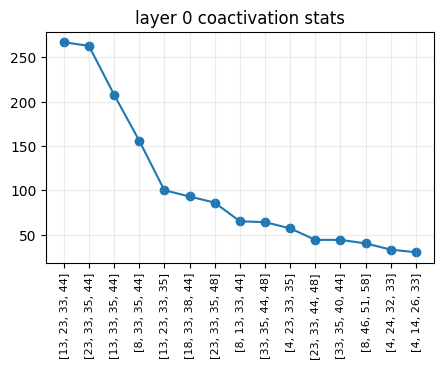

In [13]:
plot_layer_coactivation_stats(0, 4)

In [14]:
embs_subset_anatomy = all_embeddings_layer_0[all_embeddings_layer_0['task'] == 'anatomy']

In [15]:
if (False):
    saved_embs_2d_layer_0 = show_layers_from_full_space(layers=[0], 
        plot_activation_stats=True, 
        suptitle="layer 0 embeddings without mean",
        embs_only=embs_subset_anatomy.iloc[:, 3:],
        embeddings_with_meta = embs_subset_anatomy,
    )
        # tsne_algo=umap.UMAP(),
        #custom_c=hdb.labels_)

In [16]:
all_embeddings_layer_23 = parser.get_all_expert_embeddings(all_topics, [23])

anatomy !!!
conceptual_physics !!!
human_sexuality !!!
machine_learning !!!
management !!!
marketing !!!
nutrition !!!
philosophy !!!
us_foreign_policy !!!
world_religions !!!


In [17]:
embs_subset_anatomy_23 = all_embeddings_layer_23[all_embeddings_layer_23['task'] == 'anatomy']

In [18]:
if (False):
    saved_embs_2d_layer_23 = show_layers_from_full_space(layers=[23], 
        plot_activation_stats=True, 
        suptitle="layer 23 embeddings without mean",
        embs_only=embs_subset_anatomy_23.iloc[:, 3:],
        embeddings_with_meta = embs_subset_anatomy_23,
    )
    # tsne_algo=umap.UMAP(),
    #custom_c=hdb.labels_)

/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_mds.py:744: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9. To suppress this warning, provide some value of `n_init`.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_mds.py:754: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(


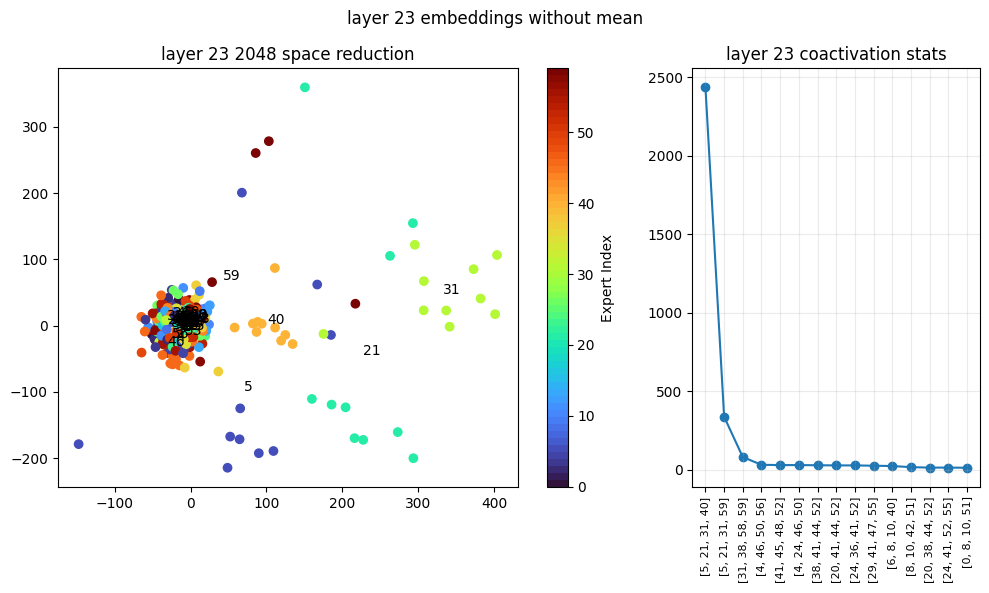

[array([[ 19.81811732,  26.18000198],
        [-20.87947792,  18.98513774],
        [  5.5258165 ,  -7.67006685],
        ...,
        [-32.03732951,   8.35319105],
        [ -8.9165965 , -20.66374744],
        [-11.53366103,   4.82164974]], shape=(598, 2))]

In [19]:
show_layers_from_full_space(layers=[23], 
    plot_activation_stats=True, 
    suptitle="layer 23 embeddings without mean",
    embs_only=embs_only_full,
    embeddings_with_meta = embeddings,
)

## Лучше обсчитывать на полных данных

In [20]:
import sys
from pathlib import Path
import torch
sys.path.insert(0, str(Path.cwd().resolve().parents[1]))
from MoE_Optimization.common.clustering_utils import MMLUBatchGenerator


In [22]:
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
import torch

#model, tokenizer = get_qwen(...)

MODEL = "Qwen/Qwen1.5-MoE-A2.7B"
DEVICE_MAP = {"": "cuda:2"}

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
)

tokenizer = AutoTokenizer.from_pretrained(MODEL, trust_remote_code=True)
model = AutoModelForCausalLM.from_pretrained(
    MODEL,
    trust_remote_code=True,
    device_map=DEVICE_MAP,
    dtype=torch.float16,
    quantization_config=quantization_config,
    cache_dir='../../.cache',
)


Loading weights:   0%|          | 0/387 [00:00<?, ?it/s]

In [23]:
from MoE_Optimization.common.clustering_utils import SELECTED_TASKS, convert_inputs_to_tokens
from MoE_Optimization.common.expert_clusterer import ExpertClusterer


gen = MMLUBatchGenerator(subjects=SELECTED_TASKS, split='validation', batch_size=16, include_metadata=False)
example_inputs = convert_inputs_to_tokens(gen, tokenizer, model.device)
clusterer = ExpertClusterer(model, example_inputs)

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


Initialized MMLU batch generator with 5 subjects
Split: validation, Batch size: 16

📚 Loading subject 1/5: anatomy


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  ✓ Created batch with 14 questions

📚 Loading subject 2/5: machine_learning


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  ✓ Created batch with 11 questions

📚 Loading subject 3/5: management


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  ✓ Created batch with 11 questions

📚 Loading subject 4/5: philosophy


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  ✓ Created batch with 16 questions

📚 Loading subject 5/5: world_religions
  ✓ Created batch with 16 questions


In [24]:
from MoE_Optimization.common.moe_utils import discover_moe_layers
layers = discover_moe_layers(model)
layers

[MoeHandle(layer_idx=0, moe=Qwen2MoeSparseMoeBlock(
   (gate): Qwen2MoeTopKRouter()
   (experts): Qwen2MoeExperts(
     (act_fn): SiLUActivation()
   )
   (shared_expert): Qwen2MoeMLP(
     (gate_proj): Linear4bit(in_features=2048, out_features=5632, bias=False)
     (up_proj): Linear4bit(in_features=2048, out_features=5632, bias=False)
     (down_proj): Linear4bit(in_features=5632, out_features=2048, bias=False)
     (act_fn): SiLUActivation()
   )
   (shared_expert_gate): Linear4bit(in_features=2048, out_features=1, bias=False)
 ), gate=Qwen2MoeTopKRouter(), experts=Qwen2MoeExperts(
   (act_fn): SiLUActivation()
 ), kind='qwen'),
 MoeHandle(layer_idx=1, moe=Qwen2MoeSparseMoeBlock(
   (gate): Qwen2MoeTopKRouter()
   (experts): Qwen2MoeExperts(
     (act_fn): SiLUActivation()
   )
   (shared_expert): Qwen2MoeMLP(
     (gate_proj): Linear4bit(in_features=2048, out_features=5632, bias=False)
     (up_proj): Linear4bit(in_features=2048, out_features=5632, bias=False)
     (down_proj): Lin

In [25]:
handles2clusters = clusterer.create_clusters_by_PI([layers[23]])

In [26]:
handles2clusters[23]

[[44, 47],
 [57, 2],
 [30, 27, 59],
 [43, 16, 41],
 [18, 8],
 [58, 19],
 [35, 14, 42],
 [37, 28],
 [13, 25],
 [4, 11],
 [12, 45],
 [39, 15, 21],
 [38, 9],
 [24, 3],
 [20, 10],
 [56, 26],
 [51, 46],
 [32, 34],
 [50, 6],
 [5, 17],
 [29, 33],
 [7, 36],
 [0, 22],
 [53, 40],
 [1, 54],
 [49, 52],
 [55, 23],
 [31, 48]]

In [27]:
embeddings.shape

(14277, 2051)

/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_mds.py:744: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9. To suppress this warning, provide some value of `n_init`.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_mds.py:754: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(


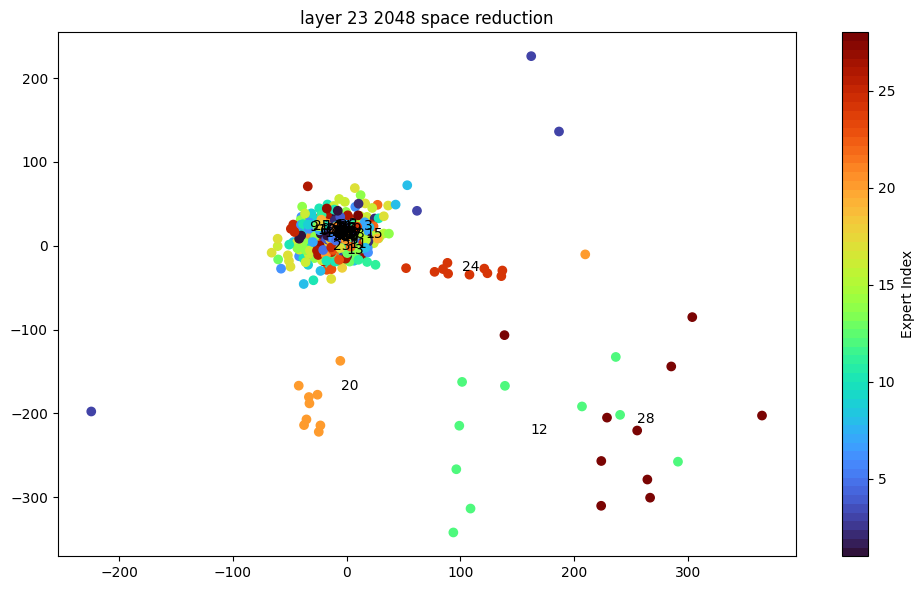

[array([[ 32.67338163,  14.52987983],
        [-19.16898531,  -6.4857617 ],
        [ -4.83952669,  30.52222153],
        ...,
        [-22.98492693,  24.97929401],
        [-29.70929185,   4.32401876],
        [ -9.34412104,   6.12207095]], shape=(598, 2))]

In [28]:
custom_c_23 = clusters_to_custom_c(handles2clusters[23], embeddings_with_meta=embeddings[embeddings['layer']==23])
show_layers_from_full_space(layers=[23], custom_c=custom_c_23, embeddings_with_meta=embeddings, embs_only=embs_only_full)

Видно раскраску, сократилась в два раза по цветам. Видно, что стратегия min PI приводит к тому, что удалённые кластеры остаются удалены. (так модель будет иметь возможность выбирать из разных независимых экспертов)

Можно попробовать стратегию max PI

In [29]:
from MoE_Optimization.common.expert_logger_data_converter import ExpertLoggerDataConverter
from MoE_Optimization.common.expert_matcher import ExpertMatcher


name2activations = clusterer._get_activations_from_gate([layers[23]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[23]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
clusters, history = ExpertMatcher.find_by_dividive_clustering(gate_PI_matrix, 
                                                        maximize_metric=True, 
                                                        log_history=True)

/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_mds.py:744: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9. To suppress this warning, provide some value of `n_init`.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_mds.py:754: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(


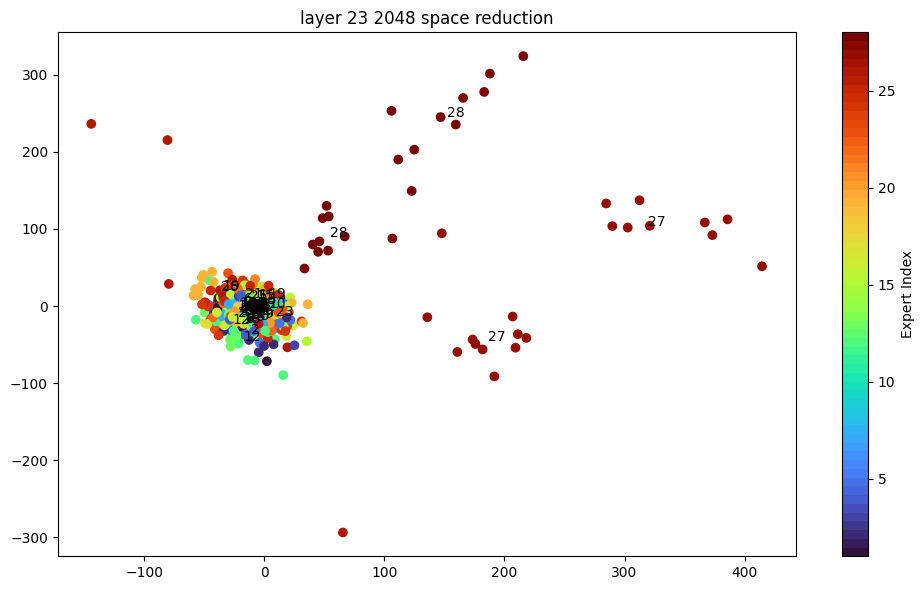

[array([[ -7.63590461,  34.95375254],
        [  0.9359625 ,   7.69017448],
        [-22.50515099, -24.4518442 ],
        ...,
        [-12.69608228,  13.36885796],
        [-19.22774748,  13.85652941],
        [-12.54890441,  -2.40416783]], shape=(598, 2))]

In [30]:
custom_c_23 = clusters_to_custom_c(clusters, embeddings_with_meta=embeddings[embeddings['layer']==23])
show_layers_from_full_space(layers=[23], custom_c=custom_c_23, embeddings_with_meta=embeddings, embs_only=embs_only_full)

Кластера разглядывать пока всё ещё не удобно. Введём метрики.

calinski-harabasz - для общей оценки результата кластеризации, межгрупповая дисперсия/внутригрупповая
silhouette score - для всех точек между кластерами мерит среднюю удалённость, чем выше тем лучше, точки ближе к своим кластерам чем к чужим.

До этого мерили кластеризацию на mixtral только сугубо для отдельных пар экспертов. То есть смотрели как два облака хорошо разделяются и как это кореллирует с популярностью их выбора.
На глаз лучше всего оказалась метрика calinski-harabarsz. Остальные плохо кореллируют.

Теперь будем использовать метрики для оценки всей кластеризации в целом.

In [31]:
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering, Birch, OPTICS
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

def evaluate_clustering_metrics(X, labels):
    # Filter out noise points (-1) for metrics that don't handle them
    mask = labels != -1
    if mask.sum() > 1:
        X_clean = X[mask]
        labels_clean = labels[mask]
        
        metrics = {
            'silhouette': silhouette_score(X_clean, labels_clean),
            'calinski_harabasz': calinski_harabasz_score(X_clean, labels_clean),
            'davies_bouldin': davies_bouldin_score(X_clean, labels_clean),
            'n_clusters': len(set(labels_clean)),
            'noise_points': (labels == -1).sum()
        }
        return metrics
    return None

In [32]:
history.__len__()

27

In [33]:
# sensitive to scale, other metrics!
# from sklearn.preprocessing import StandardScaler
# X = embs_only_full[embeddings['layer'] == 23].to_numpy(dtype=np.float64)
# X = StandardScaler().fit_transform(X)
# evaluate_clustering_metrics(X, embeddings[embeddings['layer'] == 23]['expert'])

In [34]:
evaluate_clustering_metrics(embs_only_full[embeddings['layer'] == 23].to_numpy(dtype=np.float64), embeddings[embeddings['layer'] == 23]['expert'])

{'silhouette': -0.009704582623368442,
 'calinski_harabasz': 49.43068043231336,
 'davies_bouldin': 2.0690804037873756,
 'n_clusters': 60,
 'noise_points': np.int64(0)}

Maximize PI for comparsion

In [35]:
custom_c_23 = clusters_to_custom_c(clusters, embeddings_with_meta=embeddings[embeddings['layer']==23])
evaluate_clustering_metrics(embs_only_full[embeddings['layer'] == 23].to_numpy(dtype=np.float64), custom_c_23)

{'silhouette': -0.13829640528271964,
 'calinski_harabasz': 26.327736426497538,
 'davies_bouldin': 2.9014871703423575,
 'n_clusters': 28,
 'noise_points': np.int64(0)}

Minimize PI

In [36]:
handles2clusters = clusterer.create_clusters_by_PI([layers[23]])

In [37]:
clusters = handles2clusters.items().__iter__().__next__()[1]
custom_c_23 = clusters_to_custom_c(clusters, embeddings_with_meta=embeddings[embeddings['layer']==23])
evaluate_clustering_metrics(embs_only_full[embeddings['layer'] == 23].to_numpy(dtype=np.float64), custom_c_23)

{'silhouette': -0.12594041344781087,
 'calinski_harabasz': 11.583420528627878,
 'davies_bouldin': 2.921126598257263,
 'n_clusters': 28,
 'noise_points': np.int64(0)}

In [38]:
a = [6]
a.insert(0, 5)
a

[5, 6]

In [39]:
import numpy as np
import pandas as pd
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score



def labels_from_clusters(clusters, row_experts):
    '''transforms labels to merged labels'''
    expert_to_cluster = {}
    for cluster_id, cluster in enumerate(clusters):
        for expert in cluster:
            expert_to_cluster[expert] = cluster_id
    return np.asarray([expert_to_cluster.get(expert, -1) for expert in row_experts], dtype=np.int64)



def build_history_metrics_df(history, X, row_experts):
    rows = []

    for step, entry in enumerate(history):
        clusters = entry.get("all_clusters", entry.get("clusters"))
        if clusters is None or len(clusters) < 2:
            continue

        labels = labels_from_clusters(clusters, row_experts)
        valid_mask = labels >= 0
        X_step = X[valid_mask]
        labels_step = labels[valid_mask]

        if X_step.shape[0] < 2 or np.unique(labels_step).size < 2:
            continue

        row = {
            "step": step,
            "n_clusters": len(clusters),
            "metric_of_split_cluster": entry.get("metric_of_split_cluster", np.nan),
        }
        row.update({
            key: value
            for key, value in entry.items()
            if key.startswith("total_") and key.endswith("_after_split")
        })

        try:
            row["silhouette"] = silhouette_score(X_step, labels_step)
        except Exception:
            row["silhouette"] = np.nan

        try:
            row["calinski_harabasz"] = calinski_harabasz_score(X_step, labels_step)
        except Exception:
            row["calinski_harabasz"] = np.nan

        try:
            row["davies_bouldin"] = davies_bouldin_score(X_step, labels_step)
        except Exception:
            row["davies_bouldin"] = np.nan

        rows.append(row)

    return pd.DataFrame(rows)


layer_id = 23
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df = build_history_metrics_df(history, X_layer, row_experts)
display(history_df)
print("history_df length:", len(history_df))

,step,n_clusters,metric_of_split_cluster,total_metric_after_split,silhouette,calinski_harabasz,davies_bouldin
0,0,2,0.007994,0.011479,0.039388,23.456966,2.991139
1,1,3,0.010125,0.014330,-0.111931,36.163654,5.182919
2,2,4,0.012833,0.017751,-0.117364,24.439236,5.051127
3,3,5,0.016404,0.019227,-0.170530,18.506970,4.667993
4,4,6,0.016661,0.021200,-0.202177,15.067062,4.661310
5,5,7,0.014077,0.021914,-0.236254,12.587604,4.433026
6,6,8,0.017242,0.022288,-0.229774,10.915798,4.236428
7,7,9,0.018462,0.026780,-0.169612,27.698065,4.482283
8,8,10,0.009791,0.028549,-0.166172,24.688082,4.252107
9,9,11,0.008930,0.028983,-0.165302,22.255949,4.165307


history_df length: 27


NOTE: history now from Maximize PI (if metric grows)

In [40]:
import matplotlib.pyplot as plt
import math


def plot_history_metrics(history_df, suptitle=""):
    if history_df.empty:
        print("history_df is empty")
        return

    base_columns = [
        ("n_clusters", "Number of clusters"),
        ("metric_of_split_cluster", "metric_of_split_cluster"),
        ("silhouette", "Silhouette"),
        ("calinski_harabasz", "Calinski-Harabasz"),
        ("davies_bouldin", "Davies-Bouldin"),
    ]
    total_columns = [
        (column, column)
        for column in history_df.columns
        if column.startswith("total_") and column.endswith("_after_split")
    ]
    plot_columns = base_columns + total_columns

    if not plot_columns:
        print("No metric columns found")
        return

    n_plots = len(plot_columns)
    n_cols = 3 if n_plots > 1 else 1
    n_rows = math.ceil(n_plots / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows), sharex=True)
    axes = np.atleast_1d(axes).ravel()
    
    fig.suptitle(suptitle)

    for ax, (column, title) in zip(axes, plot_columns):
        ax.plot(history_df["step"], history_df[column], marker="o", linewidth=2)
        ax.set_title(title)
        ax.set_xlabel("step")
        ax.grid(True, alpha=0.3)

    for ax in axes[n_plots:]:
        ax.axis("off")

    for ax in axes[:n_plots]:
        ax.set_xlim(history_df["step"].min(), history_df["step"].max())

    fig.tight_layout()
    plt.show()

Minimize PI

In [41]:
name2activations = clusterer._get_activations_from_gate([layers[23]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[23]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
clusters, history = ExpertMatcher.find_by_dividive_clustering(gate_PI_matrix, 
                                                        maximize_metric=False, 
                                                        log_history=True,
                                                        other_matrices_for_stats={
                                                            'EC': gate_EC_matrix
                                                        })

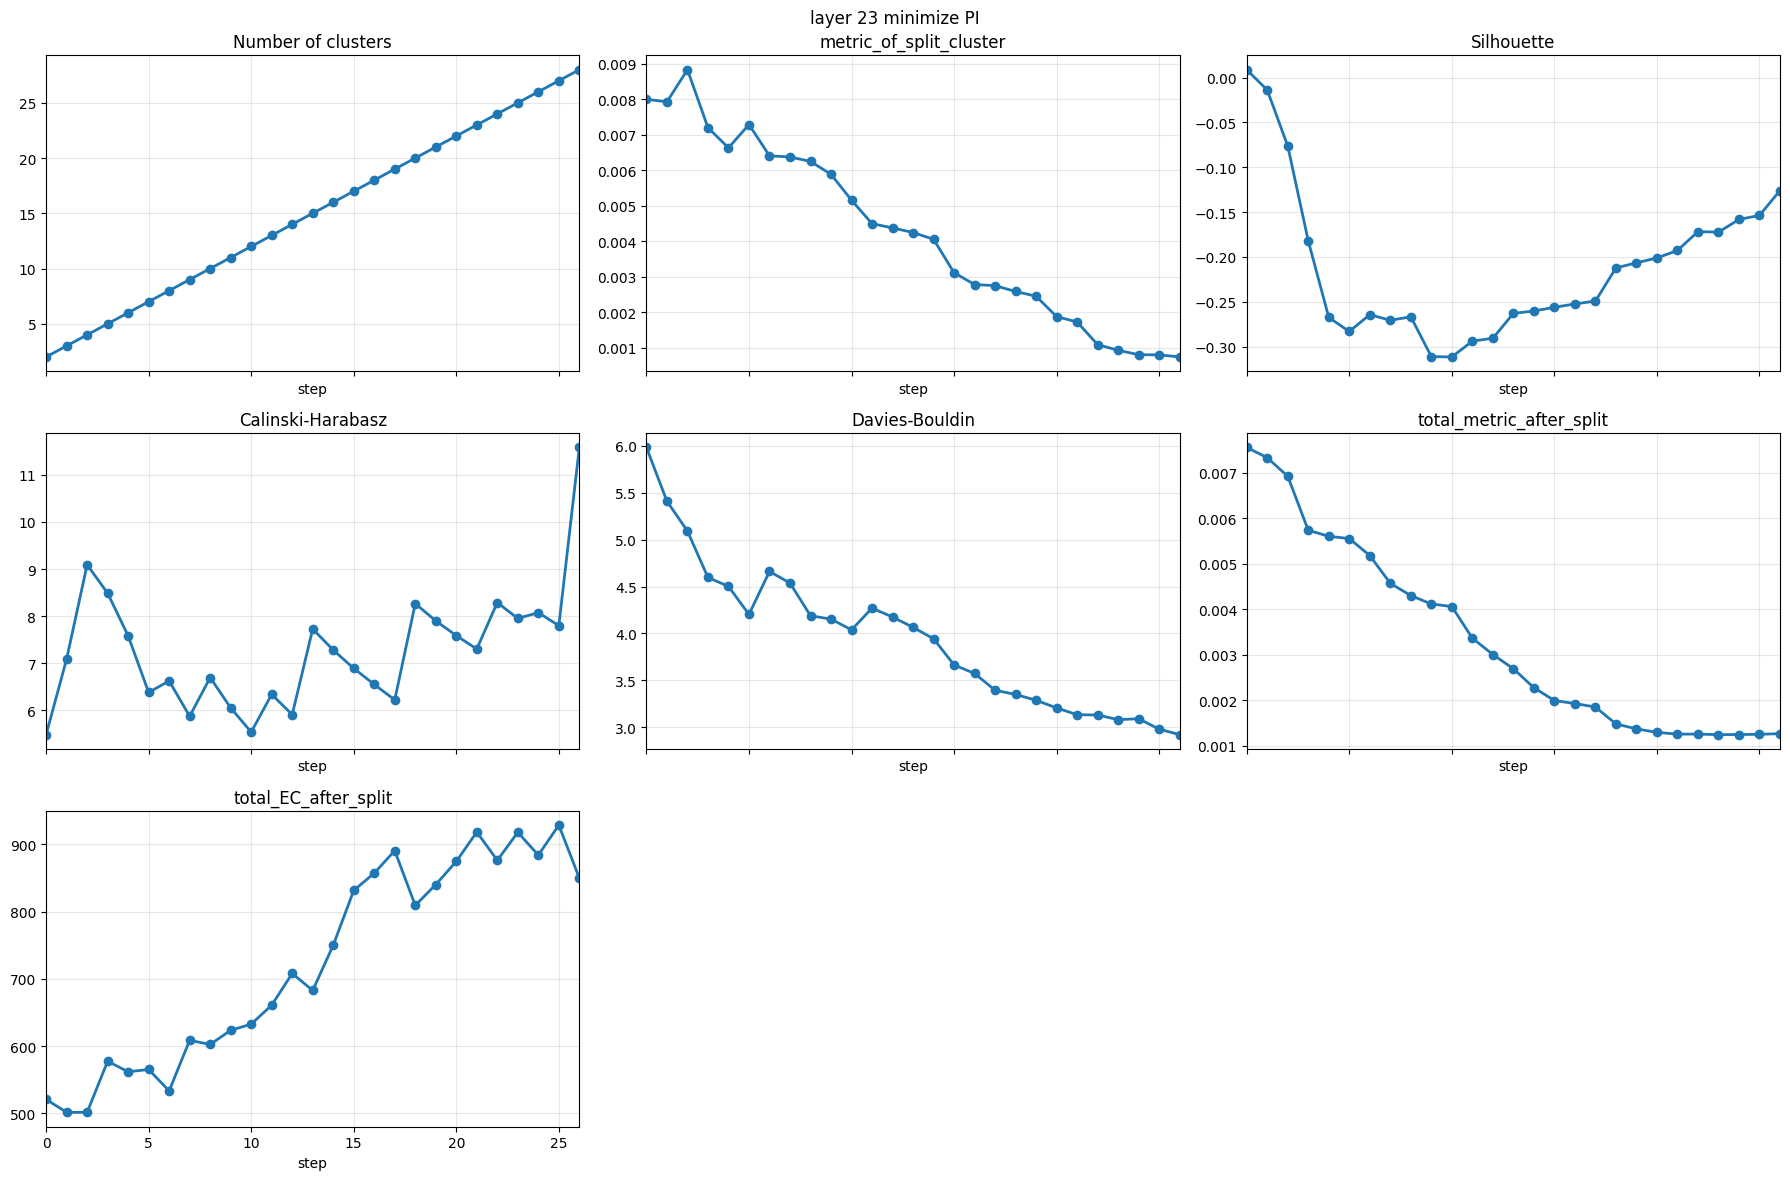

In [42]:
layer_id = 23
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df = build_history_metrics_df(history, X_layer, row_experts)
plot_history_metrics(history_df, 'layer 23 minimize PI')

lets try on full embeddings (not mean) for layer 23

In [43]:
all_embeddings_layer_23.drop(["expert", "task", "layer"], axis=1)

/usr/local/lib/python3.12/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.12/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5,emb_6,emb_7,emb_8,emb_9,...,emb_2038,emb_2039,emb_2040,emb_2041,emb_2042,emb_2043,emb_2044,emb_2045,emb_2046,emb_2047
0,-4.625000,-1.360352,-3.408203,0.334961,-2.513672,-2.847656,-2.134766,-1.212891,-2.257812,-1.765625,...,-0.153687,-0.975586,0.306641,-2.777344,-0.522461,-0.084900,1.731445,1.327148,0.563477,-2.210938
1,-0.237061,1.125000,-0.273193,1.958008,-3.373047,2.222656,-1.642578,1.476562,0.314941,-3.109375,...,-3.000000,1.572266,0.417725,3.761719,-0.005192,-0.315430,0.451172,1.512695,-1.270508,-2.003906
2,-1.536133,0.137329,-0.521484,0.537109,-0.519531,0.052765,-1.004883,2.753906,-0.154541,-2.533203,...,-1.642578,1.944336,-1.458984,2.623047,1.006836,1.344727,0.810059,0.604980,-3.996094,0.832031
3,0.906738,-0.316895,0.027145,0.142700,-0.253174,-1.541992,-0.987305,0.486328,-0.975586,1.989258,...,0.720703,2.375000,-1.658203,1.529297,-2.146484,-2.498047,1.254883,-0.478271,-0.506836,-1.825195
4,0.570312,-0.187378,-0.837402,2.966797,-1.634766,2.457031,-2.224609,2.214844,1.683594,-0.506836,...,0.545898,2.191406,-0.540527,-0.088928,0.703613,1.141602,-1.704102,4.703125,-1.902344,2.769531
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21915,0.126221,1.038086,0.808105,0.096558,0.473145,0.354736,-0.303467,0.295654,-0.557129,-0.660645,...,0.257324,-0.667480,-1.002930,0.346924,-0.699219,-0.604004,0.244507,-0.583496,-0.067139,-0.265381
21916,0.268311,0.256348,0.584961,1.046875,0.116760,0.000642,-0.143188,0.353760,-0.063232,0.115417,...,0.753418,0.867188,-0.475342,0.623535,0.172974,0.001497,0.210449,-0.234619,0.219360,0.255371
21917,-0.684082,0.169556,0.899902,-1.037109,-0.789551,1.132812,-0.950684,0.335449,0.328613,-1.533203,...,-0.061066,0.653320,-0.633301,-0.635742,-1.341797,0.711426,0.117981,-0.730957,0.060760,-0.428955
21918,-0.061371,1.128906,1.092773,-0.604004,1.100586,0.212891,-0.065430,-1.112305,0.421631,0.102356,...,-0.422363,0.253662,0.183105,-0.704590,0.150757,0.989746,-0.641602,0.608398,-0.094055,0.150391


In [44]:
name2activations = clusterer._get_activations_from_gate([layers[23]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[23]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
clusters, history = ExpertMatcher.find_by_dividive_clustering(gate_PI_matrix, 
                                                        maximize_metric=False, 
                                                        log_history=True,
                                                        other_matrices_for_stats={
                                                            'EC': gate_EC_matrix
                                                        })

layer_id = 23
layer_mask = all_embeddings_layer_23["layer"].eq(layer_id)
X_layer = all_embeddings_layer_23.drop(["expert", "task", "layer"], axis=1).loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = all_embeddings_layer_23.loc[layer_mask, "expert"].to_numpy()

history_df = build_history_metrics_df(history, X_layer, row_experts)
plot_history_metrics(history_df, 'layer 23 minimize PI')

KeyboardInterrupt: 

In [45]:
name2activations = clusterer._get_activations_from_gate([layers[11]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[11]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
clusters, history = ExpertMatcher.find_by_dividive_clustering(gate_PI_matrix, 
                                                        maximize_metric=False, 
                                                        log_history=True,
                                                        other_matrices_for_stats={
                                                            'EC': gate_EC_matrix
                                                        })

In [46]:
all_embeddings_layer_23.drop(["expert", "task", "layer"], axis=1)

/usr/local/lib/python3.12/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.12/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5,emb_6,emb_7,emb_8,emb_9,...,emb_2038,emb_2039,emb_2040,emb_2041,emb_2042,emb_2043,emb_2044,emb_2045,emb_2046,emb_2047
0,-4.625000,-1.360352,-3.408203,0.334961,-2.513672,-2.847656,-2.134766,-1.212891,-2.257812,-1.765625,...,-0.153687,-0.975586,0.306641,-2.777344,-0.522461,-0.084900,1.731445,1.327148,0.563477,-2.210938
1,-0.237061,1.125000,-0.273193,1.958008,-3.373047,2.222656,-1.642578,1.476562,0.314941,-3.109375,...,-3.000000,1.572266,0.417725,3.761719,-0.005192,-0.315430,0.451172,1.512695,-1.270508,-2.003906
2,-1.536133,0.137329,-0.521484,0.537109,-0.519531,0.052765,-1.004883,2.753906,-0.154541,-2.533203,...,-1.642578,1.944336,-1.458984,2.623047,1.006836,1.344727,0.810059,0.604980,-3.996094,0.832031
3,0.906738,-0.316895,0.027145,0.142700,-0.253174,-1.541992,-0.987305,0.486328,-0.975586,1.989258,...,0.720703,2.375000,-1.658203,1.529297,-2.146484,-2.498047,1.254883,-0.478271,-0.506836,-1.825195
4,0.570312,-0.187378,-0.837402,2.966797,-1.634766,2.457031,-2.224609,2.214844,1.683594,-0.506836,...,0.545898,2.191406,-0.540527,-0.088928,0.703613,1.141602,-1.704102,4.703125,-1.902344,2.769531
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21915,0.126221,1.038086,0.808105,0.096558,0.473145,0.354736,-0.303467,0.295654,-0.557129,-0.660645,...,0.257324,-0.667480,-1.002930,0.346924,-0.699219,-0.604004,0.244507,-0.583496,-0.067139,-0.265381
21916,0.268311,0.256348,0.584961,1.046875,0.116760,0.000642,-0.143188,0.353760,-0.063232,0.115417,...,0.753418,0.867188,-0.475342,0.623535,0.172974,0.001497,0.210449,-0.234619,0.219360,0.255371
21917,-0.684082,0.169556,0.899902,-1.037109,-0.789551,1.132812,-0.950684,0.335449,0.328613,-1.533203,...,-0.061066,0.653320,-0.633301,-0.635742,-1.341797,0.711426,0.117981,-0.730957,0.060760,-0.428955
21918,-0.061371,1.128906,1.092773,-0.604004,1.100586,0.212891,-0.065430,-1.112305,0.421631,0.102356,...,-0.422363,0.253662,0.183105,-0.704590,0.150757,0.989746,-0.641602,0.608398,-0.094055,0.150391


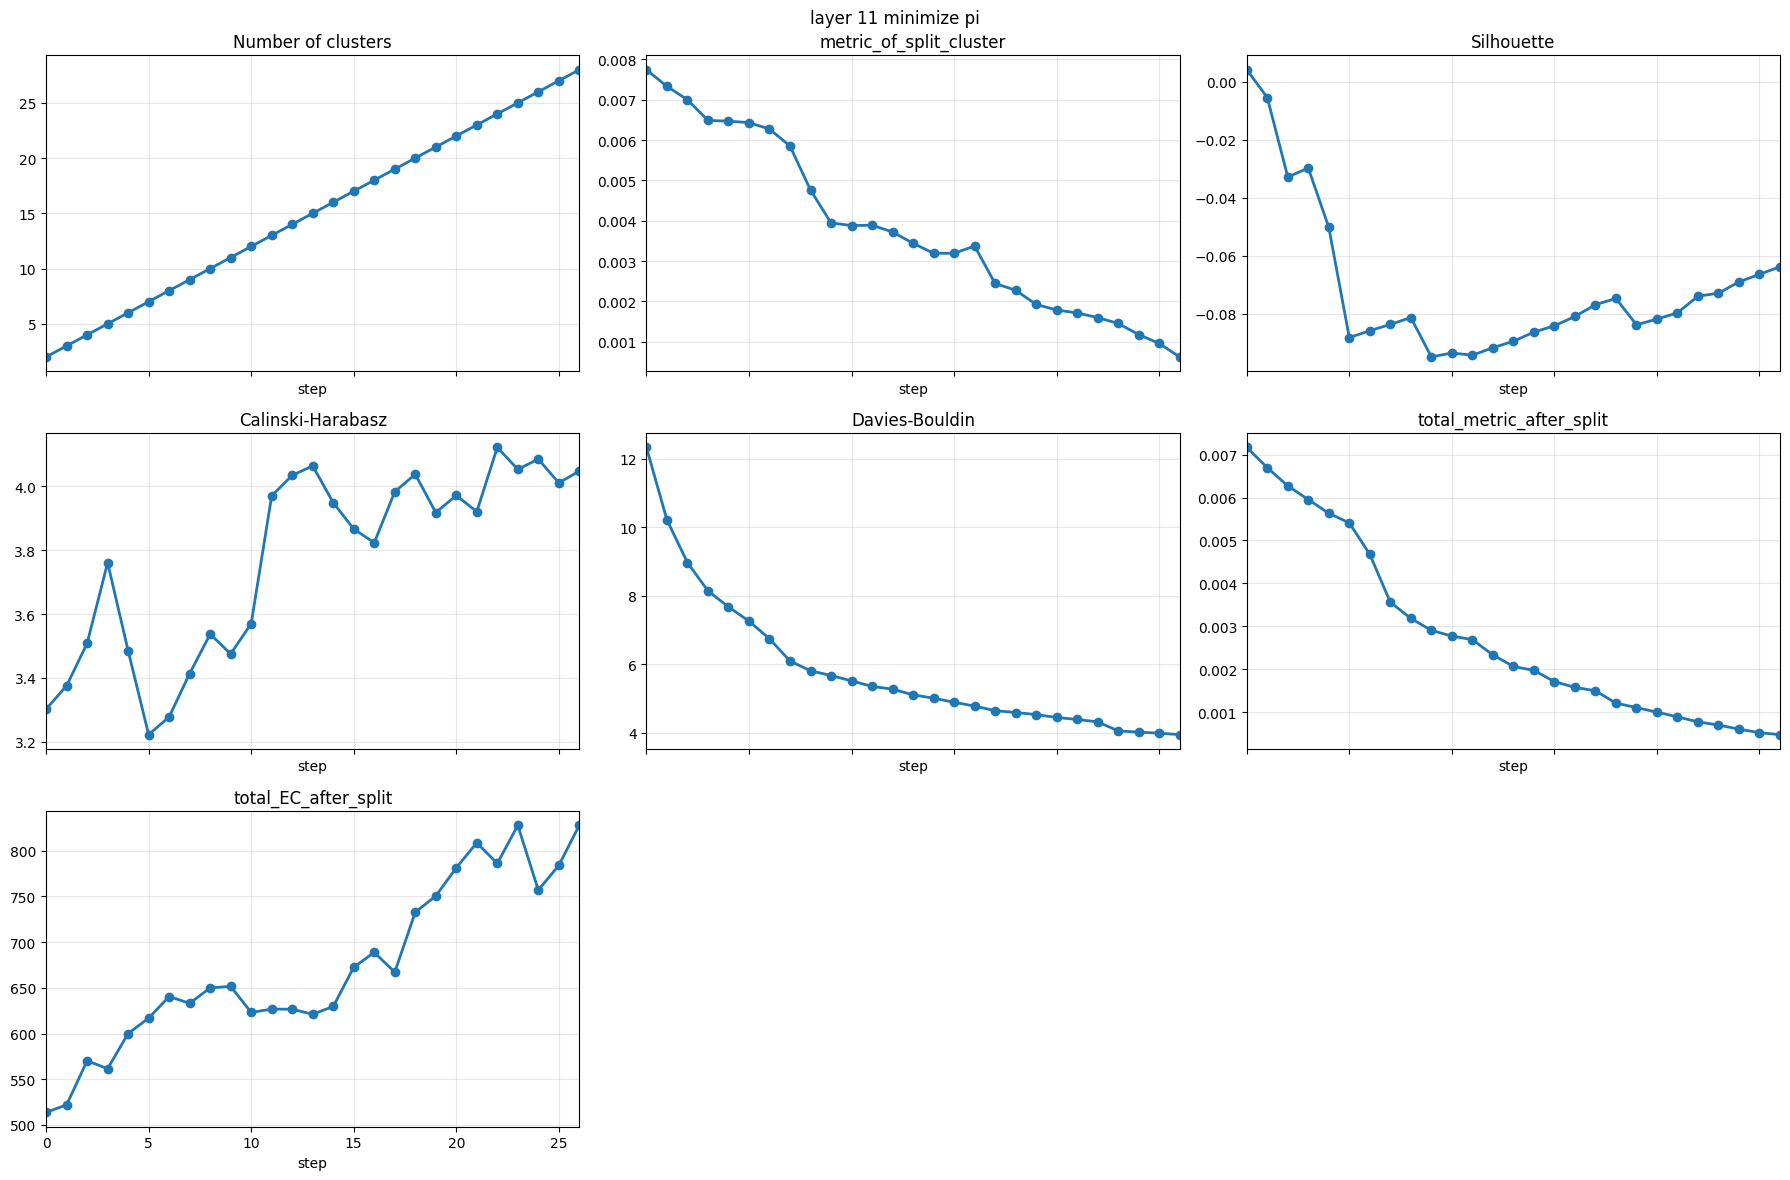

In [47]:
layer_id = 11
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df = build_history_metrics_df(history, X_layer, row_experts)
plot_history_metrics(history_df, 'layer 11 minimize pi')

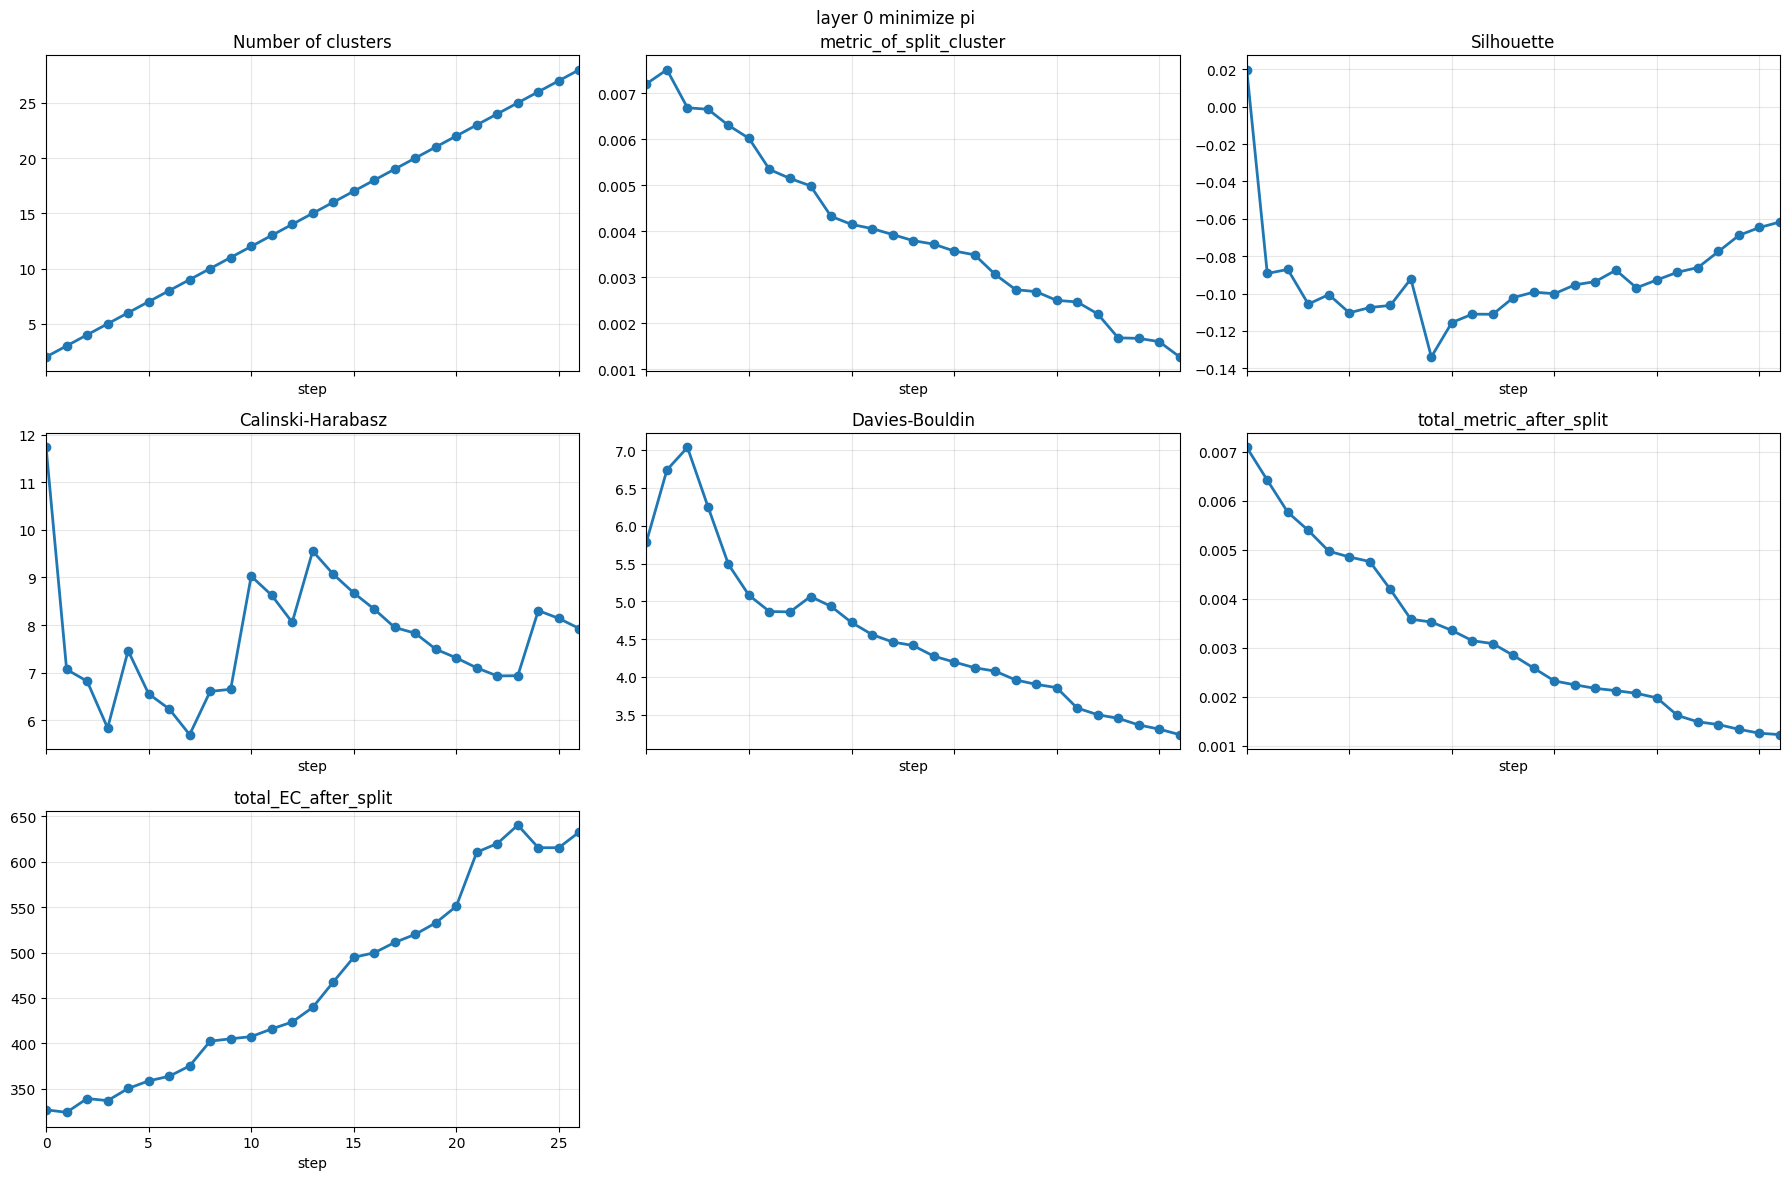

In [48]:
name2activations = clusterer._get_activations_from_gate([layers[0]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[0]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
clusters, history = ExpertMatcher.find_by_dividive_clustering(gate_PI_matrix, 
                                                        maximize_metric=False, 
                                                        log_history=True,
                                                        other_matrices_for_stats={
                                                            'EC': gate_EC_matrix
                                                        })


layer_id = 0
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df_0 = build_history_metrics_df(history, X_layer, row_experts)
plot_history_metrics(history_df_0, 'layer 0 minimize pi')

max ec

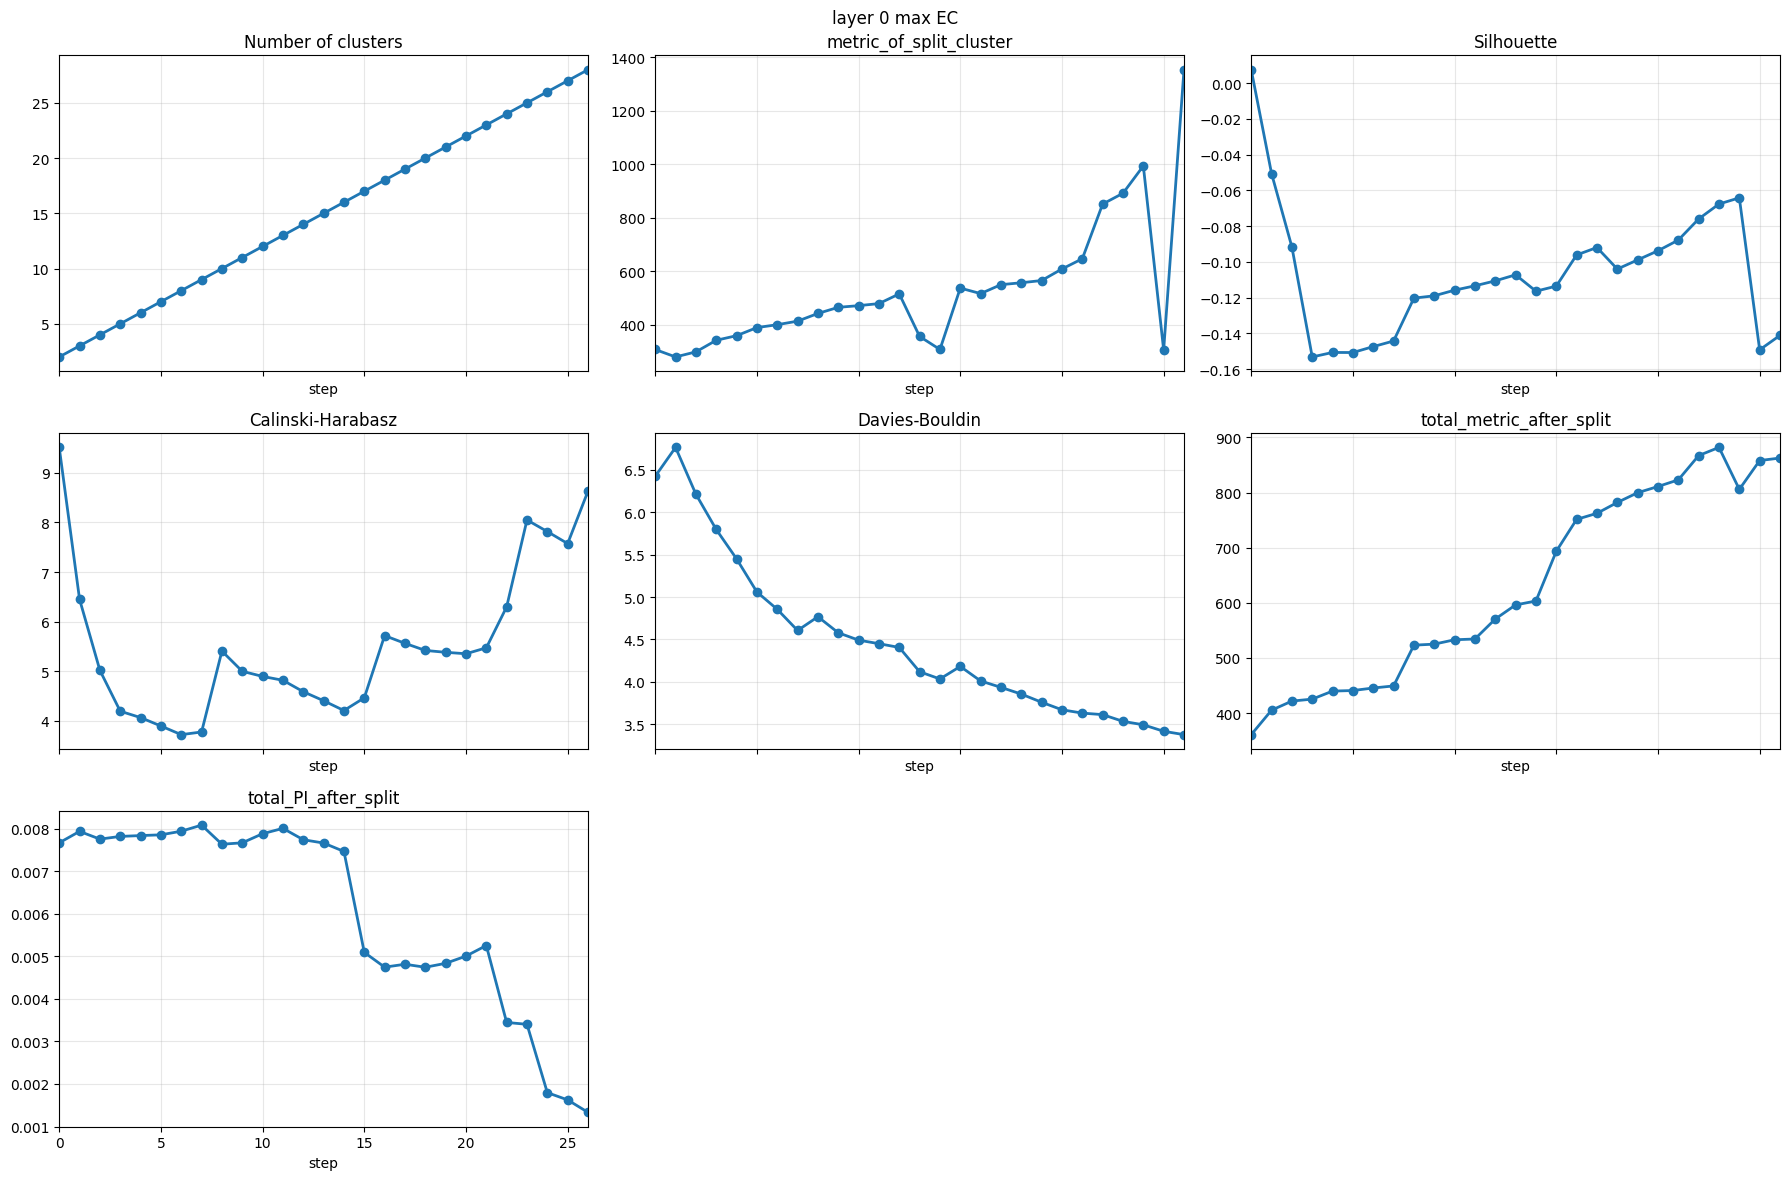

In [88]:
name2activations = clusterer._get_activations_from_gate([layers[0]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[0]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
clusters, history = ExpertMatcher.find_by_dividive_clustering(gate_EC_matrix, 
                                                        maximize_metric=True, 
                                                        log_history=True,
                                                        other_matrices_for_stats={
                                                            'PI': gate_PI_matrix
                                                        })


layer_id = 0
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df_0_max_ec = build_history_metrics_df(history, X_layer, row_experts)
plot_history_metrics(history_df_0_max_ec, 'layer 0 max EC')

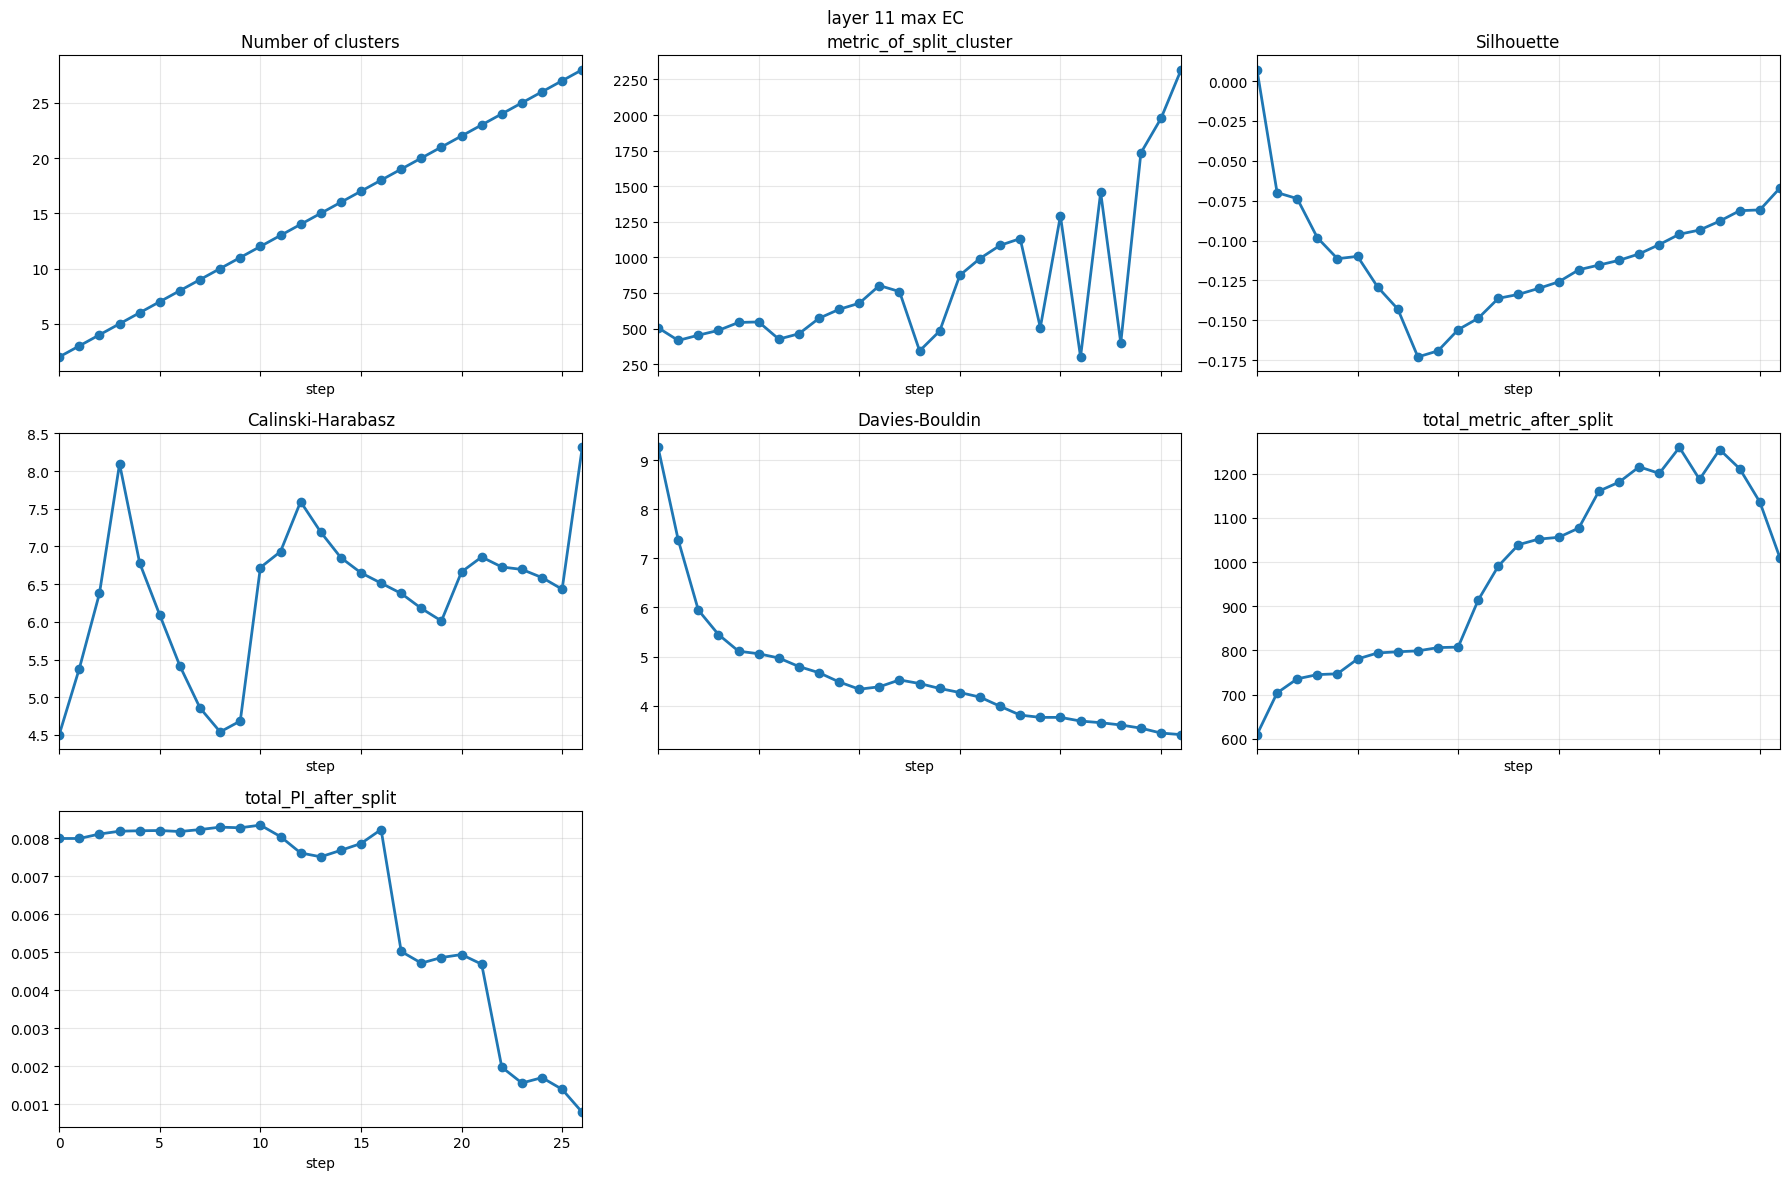

In [102]:
name2activations = clusterer._get_activations_from_gate([layers[11]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[11]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
clusters, history = ExpertMatcher.find_by_dividive_clustering(gate_EC_matrix, 
                                                        maximize_metric=True, 
                                                        log_history=True,
                                                        other_matrices_for_stats={
                                                            'PI': gate_PI_matrix
                                                        })


layer_id = 0
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df_11_max_ec = build_history_metrics_df(history, X_layer, row_experts)
plot_history_metrics(history_df_11_max_ec, 'layer 11 max EC')

In [51]:
##type here

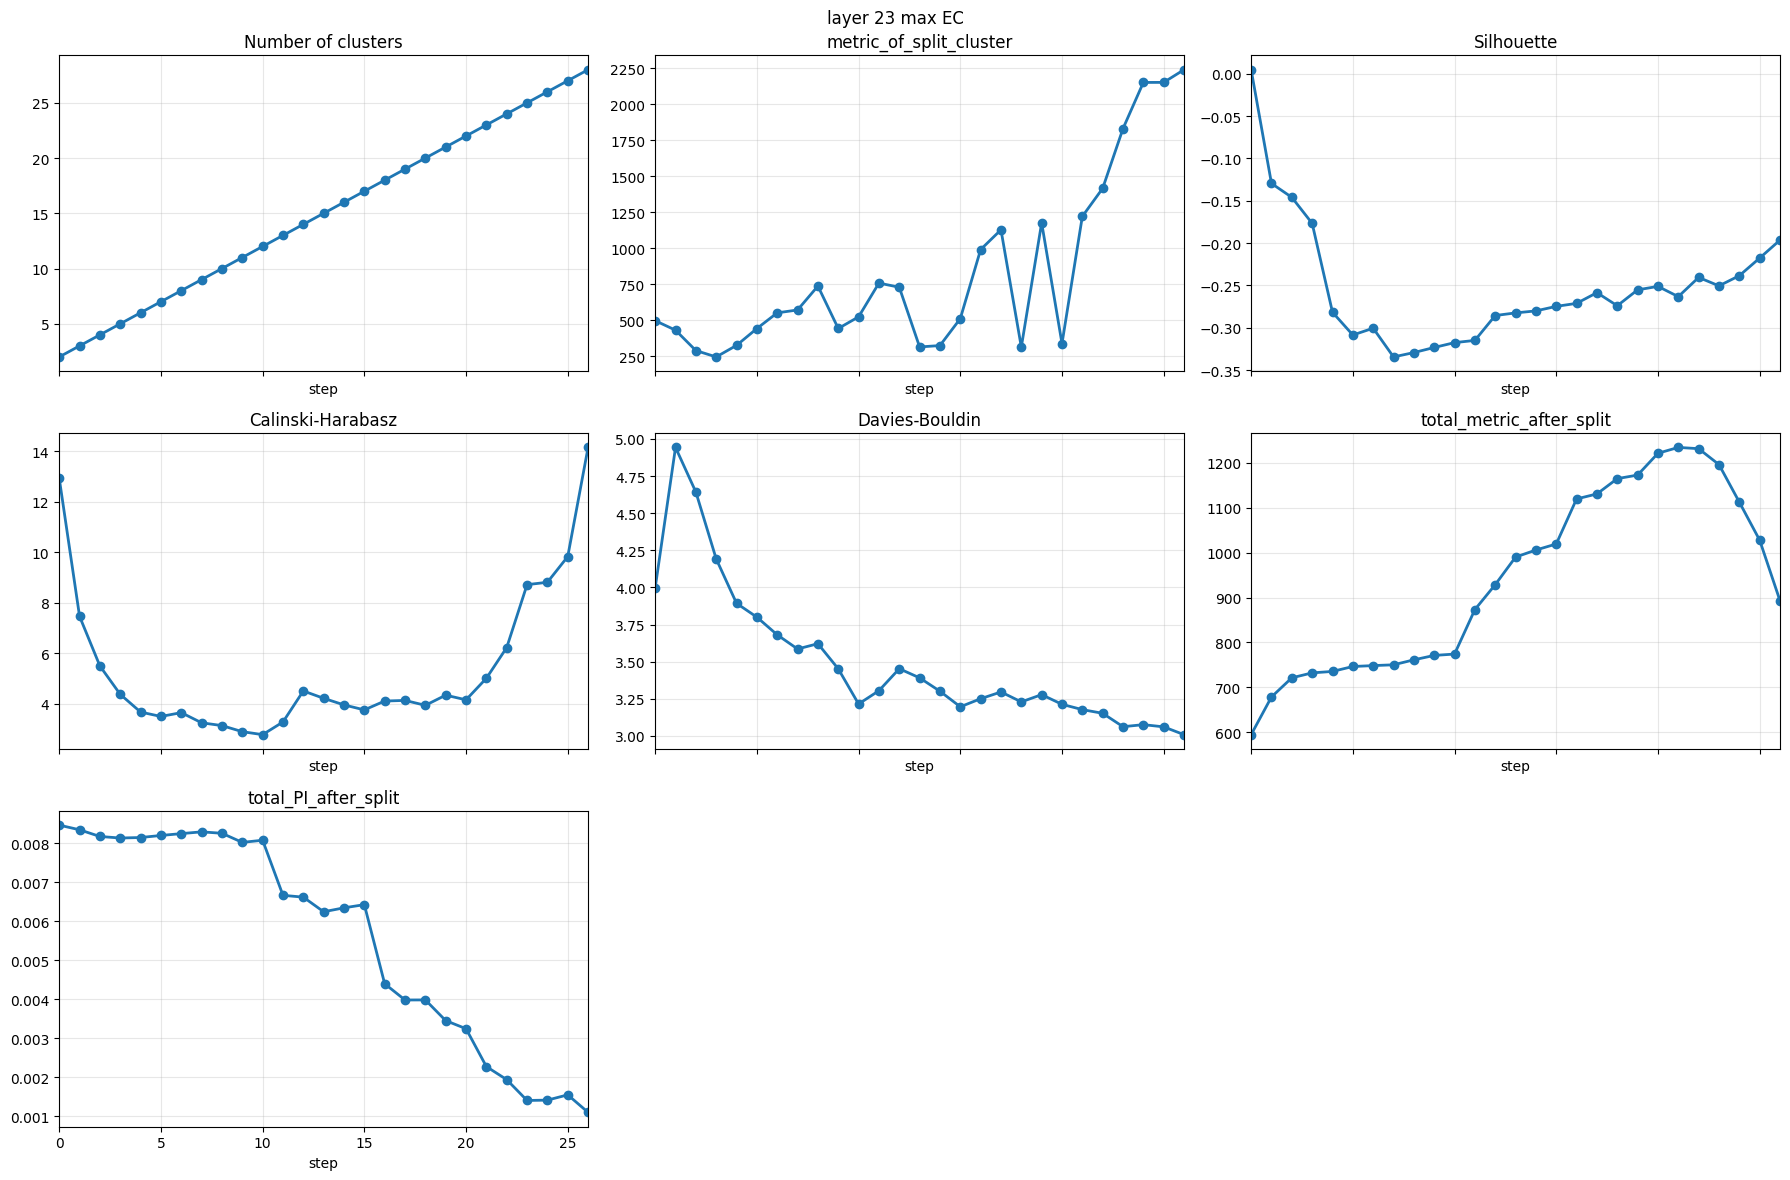

In [74]:
name2activations = clusterer._get_activations_from_gate([layers[23]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[23]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
clusters, history = ExpertMatcher.find_by_dividive_clustering(gate_EC_matrix, 
                                                        maximize_metric=True, 
                                                        log_history=True,
                                                        other_matrices_for_stats={
                                                            'PI': gate_PI_matrix
                                                        })


layer_id = 23
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df_23_max_EC = build_history_metrics_df(history, X_layer, row_experts)
plot_history_metrics(history_df_23_max_EC, 'layer 23 max EC')

In [53]:
##add method here

In [54]:
evaluate_clustering_metrics(embs_only_full[embeddings['layer'] == 23].to_numpy(dtype=np.float64), embeddings[embeddings['layer'] == 23]['expert'])

{'silhouette': -0.009704582623368442,
 'calinski_harabasz': 49.43068043231336,
 'davies_bouldin': 2.0690804037873756,
 'n_clusters': 60,
 'noise_points': np.int64(0)}

In [55]:
evaluate_clustering_metrics(all_embeddings_layer_23[all_embeddings_layer_23['layer'] == 23].drop(['expert', 'layer', 'task'], axis=1).to_numpy(dtype=np.float64), all_embeddings_layer_23[all_embeddings_layer_23['layer'] == 23]['expert'])

{'silhouette': -0.007009798020605489,
 'calinski_harabasz': 575.3535266960275,
 'davies_bouldin': 4.89159101902743,
 'n_clusters': 60,
 'noise_points': np.int64(0)}

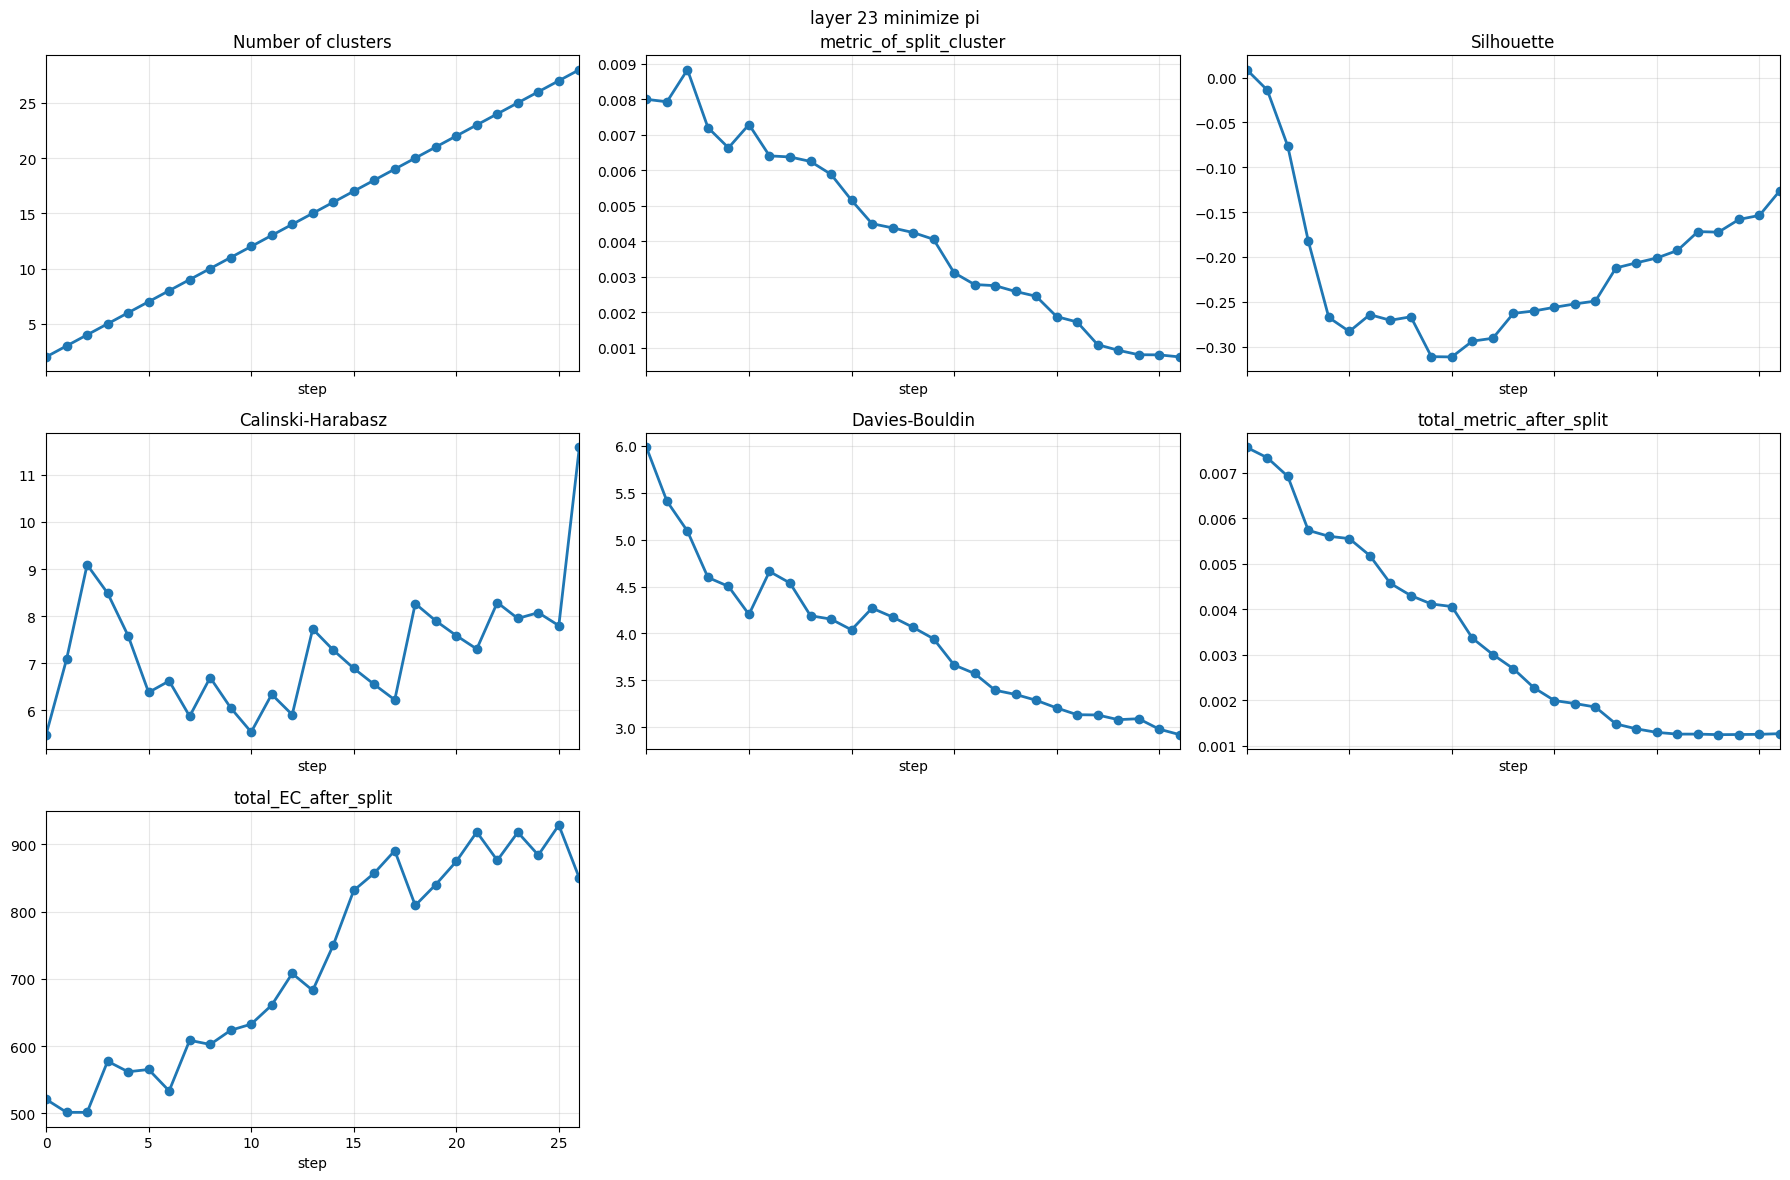

In [56]:
name2activations = clusterer._get_activations_from_gate([layers[23]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[23]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
clusters, history = ExpertMatcher.find_by_dividive_clustering(gate_PI_matrix, 
                                                        maximize_metric=False, 
                                                        log_history=True,
                                                        other_matrices_for_stats={
                                                            'EC': gate_EC_matrix
                                                        })


layer_id = 23
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df_23 = build_history_metrics_df(history, X_layer, row_experts)
plot_history_metrics(history_df_23, 'layer 23 minimize pi')

In [57]:
evaluate_clustering_metrics(embs_only_full[embeddings['layer'] == 0].to_numpy(dtype=np.float64), embeddings[embeddings['layer'] == 0]['expert'])

{'silhouette': 0.017782165303674418,
 'calinski_harabasz': 14.73446690113276,
 'davies_bouldin': 2.3535113628948667,
 'n_clusters': 60,
 'noise_points': np.int64(0)}

In [58]:
history_df

,step,n_clusters,metric_of_split_cluster,total_metric_after_split,total_PI_after_split,silhouette,calinski_harabasz,davies_bouldin
0,0,2,497.016314,594.550000,0.008468,0.004729,12.929388,3.996676
1,1,3,430.930316,678.510762,0.008349,-0.129613,7.455217,4.943183
2,2,4,289.409189,721.196136,0.008177,-0.146046,5.488209,4.642560
3,3,5,245.121629,732.185864,0.008137,-0.176788,4.364153,4.192155
4,4,6,325.402751,735.417964,0.008150,-0.281775,3.662421,3.893051
5,5,7,442.339042,746.401616,0.008203,-0.308656,3.487870,3.799873
6,6,8,551.416667,748.389151,0.008250,-0.300614,3.640033,3.680685
7,7,9,571.366659,750.182150,0.008296,-0.334552,3.237113,3.585448
8,8,10,737.596801,761.243218,0.008259,-0.329405,3.126263,3.621011
9,9,11,442.674851,771.093697,0.008026,-0.323389,2.885325,3.451860


Слишком много пересекающихся факторов, которые пока не понятно как разделить. У кластеров есть: 1) плотность 2) расстояние до центра 3) расстояние до других кластеров 4) угол 5) размер или вытянутость 6) подпространство? принципал углы?

Помимо этого в статистику не понятно полностью как они берутся. Да, первыми идут самые удалённые и самые "разнородные", но что можно сказать про всех остальных - сложно.

Поэтому и разбиение основанное на популярности будет хорошо работать только для топ кластеров-экспертов. Как объединять остальных - не ясно.
Не была найдена чёткая корелляция между миром (метриками) популярности и метриками кластеров.

И последнее: метрики вообще могут ничего не показывать, так как реальный результат - это прогон модели, а не то, как расположены кластеры.

На завтра: добавить на выбор какую метрику использовать кроме PI (написать разные методы)
Добавить критерии остановки (тоже на выбор можно) + выбрать перемножение ec*pi или совместную метрику. Выбрать метрику локтя.


1) методы pi и ec
2) остановки pi и ec 
3) перемножение pi и ec
4) фронт pi
5) кластеризацие снизу, спаривание

In [59]:
import numpy as np
from typing import Optional

from MoE_Optimization.common.clustering_utils import _weighted_average_cluster_metric


def find_by_agglomerative_clustering(
    adjacency_matrix_of_experts,
    maximize_metric=False,
    log_history=False,
    other_matrices_for_stats: Optional[dict[str, np.ndarray]] = None,
):
    '''
    Greedy matching over all edges.

    Build a queue of all expert pairs, sort it by PI, and then keep selecting
    edges whose endpoints are still unused. The result is a set of disjoint
    pairs plus singleton leftovers.

    Signature intentionally matches find_by_dividive_clustering.
    '''
    if adjacency_matrix_of_experts.ndim != 2 or adjacency_matrix_of_experts.shape[0] != adjacency_matrix_of_experts.shape[1]:
        raise ValueError('adjacency_matrix_of_experts must be a square matrix')

    score_mat = np.asarray(adjacency_matrix_of_experts, dtype=np.float64)
    n_experts = score_mat.shape[0]

    if n_experts == 0:
        return [], []
    if n_experts == 1:
        return [[0]], []

    edge_queue = [
        (float(score_mat[i, j]), i, j)
        for i in range(n_experts)
        for j in range(i + 1, n_experts)
    ]

    if maximize_metric:
        edge_queue.sort(key=lambda item: (-item[0], item[1], item[2]))
    else:
        edge_queue.sort(key=lambda item: (item[0], item[1], item[2]))

    used_vertices = set()
    clusters = []
    history = []

    for score, i, j in edge_queue:
        if i in used_vertices or j in used_vertices:
            continue

        used_vertices.add(i)
        used_vertices.add(j)
        clusters.append([i, j])

    if log_history:
        step_dict = {
            'step': len(history) + 1,
            'all_clusters': clusters,
            "total_metric_after_split": _weighted_average_cluster_metric(adjacency_matrix_of_experts, clusters),

        }
        if other_matrices_for_stats is not None:
            for key in other_matrices_for_stats.keys():
                step_dict[f'total_{key}_after_split'] = _weighted_average_cluster_metric(other_matrices_for_stats[key], clusters)
        history.append(step_dict)

    return clusters, history


In [60]:
name2activations = clusterer._get_activations_from_gate([layers[23]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[23]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
clusters, history = find_by_agglomerative_clustering(gate_PI_matrix, 
                                                        maximize_metric=False, 
                                                        log_history=True,
                                                        other_matrices_for_stats={
                                                            'EC': gate_EC_matrix
                                                        })


layer_id = 23
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df = build_history_metrics_df(history, X_layer, row_experts)
history_df
# plot_history_metrics(history_df, 'layer 23 minimize pi')

,step,n_clusters,metric_of_split_cluster,total_metric_after_split,total_EC_after_split,silhouette,calinski_harabasz,davies_bouldin
0,0,30,NaN,0.000299,1028.315555,-0.149812,13.251211,2.866002


compare with dividive and initial

In [61]:
history_df_23.tail(1)

,step,n_clusters,metric_of_split_cluster,total_metric_after_split,total_EC_after_split,silhouette,calinski_harabasz,davies_bouldin
26,26,28,0.000743,0.001264,849.757859,-0.12594,11.583421,2.921127


In [62]:
evaluate_clustering_metrics(embs_only_full[embeddings['layer'] == 23].to_numpy(dtype=np.float64), embeddings[embeddings['layer'] == 23]['expert'])

{'silhouette': -0.009704582623368442,
 'calinski_harabasz': 49.43068043231336,
 'davies_bouldin': 2.0690804037873756,
 'n_clusters': 60,
 'noise_points': np.int64(0)}

Виден большой перекос оригинальной метрики и получившихся. Кластеризация снизу лучше.

layer 0...

In [63]:
name2activations = clusterer._get_activations_from_gate([layers[0]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[0]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
clusters, history = find_by_agglomerative_clustering(gate_PI_matrix, 
                                                        maximize_metric=False, 
                                                        log_history=True,
                                                        other_matrices_for_stats={
                                                            'EC': gate_EC_matrix
                                                        })


layer_id = 0
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df = build_history_metrics_df(history, X_layer, row_experts)
history_df
# plot_history_metrics(history_df, 'layer 23 minimize pi')

,step,n_clusters,metric_of_split_cluster,total_metric_after_split,total_EC_after_split,silhouette,calinski_harabasz,davies_bouldin
0,0,30,NaN,0.000208,933.0,-0.058893,8.422899,3.430876


In [64]:
history_df_0.tail(1)

,step,n_clusters,metric_of_split_cluster,total_metric_after_split,total_EC_after_split,silhouette,calinski_harabasz,davies_bouldin
26,26,28,0.001266,0.001223,632.709609,-0.061705,7.926204,3.235579


In [65]:
evaluate_clustering_metrics(embs_only_full[embeddings['layer'] == 0].to_numpy(dtype=np.float64), embeddings[embeddings['layer'] == 0]['expert'])

{'silhouette': 0.017782165303674418,
 'calinski_harabasz': 14.73446690113276,
 'davies_bouldin': 2.3535113628948667,
 'n_clusters': 60,
 'noise_points': np.int64(0)}

layer 7

In [66]:
evaluate_clustering_metrics(embs_only_full[embeddings['layer'] == 7].to_numpy(dtype=np.float64), embeddings[embeddings['layer'] == 7]['expert'])

{'silhouette': -0.08619771138613605,
 'calinski_harabasz': 4.8557384162781005,
 'davies_bouldin': 2.7532257517980674,
 'n_clusters': 60,
 'noise_points': np.int64(0)}

В целом, кажется, лучше всего метрика calinski_harabasz кореллирует с тем, как распределены популярности в слое. Если они распределены более плавно, то и calinski меньше (наибольшая плавность в слое 7). Если же наоборот есть перекос в сторону популярных экспертов, то будет и большая метрика.

Так же, кажется, попарное объединение снизу выглядит чуть лучше, опять же по метрике calinski, чем объединение сверху.

In [67]:
name2activations = clusterer._get_activations_from_gate([layers[7]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[7]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
clusters, history = find_by_agglomerative_clustering(gate_PI_matrix, 
                                                        maximize_metric=False, 
                                                        log_history=True,
                                                        other_matrices_for_stats={
                                                            'EC': gate_EC_matrix
                                                        })


layer_id = 7
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df = build_history_metrics_df(history, X_layer, row_experts)
history_df
# plot_history_metrics(history_df, 'layer 23 minimize pi')

,step,n_clusters,metric_of_split_cluster,total_metric_after_split,total_EC_after_split,silhouette,calinski_harabasz,davies_bouldin
0,0,30,NaN,0.001807,1033.401389,-0.090069,4.00848,3.769412


In [68]:
name2activations = clusterer._get_activations_from_gate([layers[7]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[7]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
clusters, history = ExpertMatcher.find_by_dividive_clustering(gate_PI_matrix, 
                                                        maximize_metric=False, 
                                                        log_history=True,
                                                        other_matrices_for_stats={
                                                            'EC': gate_EC_matrix
                                                        })


layer_id = 7
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df = build_history_metrics_df(history, X_layer, row_experts)
history_df.tail(1)
# plot_history_metrics(history_df, 'layer 23 minimize pi')

,step,n_clusters,metric_of_split_cluster,total_metric_after_split,total_EC_after_split,silhouette,calinski_harabasz,davies_bouldin
26,26,28,0.0,0.000497,846.787039,-0.125184,3.996635,3.984192


#TODO мусор выдаёт, проверить, как объединяются вершины.

In [69]:
import numpy as np
from typing import Optional


def find_by_agglomerative_clustering_2(
    adjacency_matrix_of_experts,
    maximize_metric=False,
    log_history=False,
    other_matrices_for_stats: Optional[dict[str, np.ndarray]] = None,
):
    '''
    Bottom-up agglomerative clustering over all edges.

    The algorithm builds a queue of all expert pairs, sorts it by PI, and then
    greedily adds an edge only if it connects two different current components.
    Merging continues until every expert belongs to a component of size at least 2
    so that each expert has at least one incident edge.

    Signature intentionally matches find_by_dividive_clustering.
    '''
    if adjacency_matrix_of_experts.ndim != 2 or adjacency_matrix_of_experts.shape[0] != adjacency_matrix_of_experts.shape[1]:
        raise ValueError('adjacency_matrix_of_experts must be a square matrix')

    score_mat = np.asarray(adjacency_matrix_of_experts, dtype=np.float64)
    n_experts = score_mat.shape[0]

    if n_experts == 0:
        return [], []
    if n_experts == 1:
        return [[0]], []

    edge_queue = [
        (float(score_mat[i, j]), i, j)
        for i in range(n_experts)
        for j in range(i + 1, n_experts)
    ]

    if maximize_metric:
        edge_queue.sort(key=lambda item: (-item[0], item[1], item[2]))
    else:
        edge_queue.sort(key=lambda item: (item[0], item[1], item[2]))

    parent = list(range(n_experts))
    component_size = [1] * n_experts
    selected_edges = []
    history = []
    singleton_components = n_experts

    def find(node):
        while parent[node] != node:
            parent[node] = parent[parent[node]]
            node = parent[node]
        return node

    def union(left, right):
        left_root = find(left)
        right_root = find(right)
        if left_root == right_root:
            return False

        if component_size[left_root] < component_size[right_root]:
            left_root, right_root = right_root, left_root

        parent[right_root] = left_root
        component_size[left_root] += component_size[right_root]
        return True

    def current_clusters():
        clusters_by_root = {}
        for node in range(n_experts):
            root = find(node)
            clusters_by_root.setdefault(root, []).append(node)
        return sorted(clusters_by_root.values(), key=lambda cluster: (len(cluster), cluster))

    for score, i, j in edge_queue:
        left_root = find(i)
        right_root = find(j)
        if left_root == right_root:
            continue

        left_size = component_size[left_root]
        right_size = component_size[right_root]
        if not union(left_root, right_root):
            continue

        selected_edges.append((score, i, j))
        if left_size == 1:
            singleton_components -= 1
        if right_size == 1:
            singleton_components -= 1

        if log_history:
            step_dict = {
                'step': len(selected_edges),
                'merged_pair': [i, j],
                'pair_score': float(score),
                'singleton_components_left': singleton_components,
                'all_clusters': current_clusters(),
                "total_metric_after_split": _weighted_average_cluster_metric(adjacency_matrix_of_experts, current_clusters()),
            }
            if other_matrices_for_stats is not None:
                for key in other_matrices_for_stats.keys():
                    step_dict[f'total_{key}_after_split'] = _weighted_average_cluster_metric(other_matrices_for_stats[key], current_clusters())
            history.append(step_dict)

        if singleton_components == 0:
            break

    clusters = current_clusters()
    return clusters, history


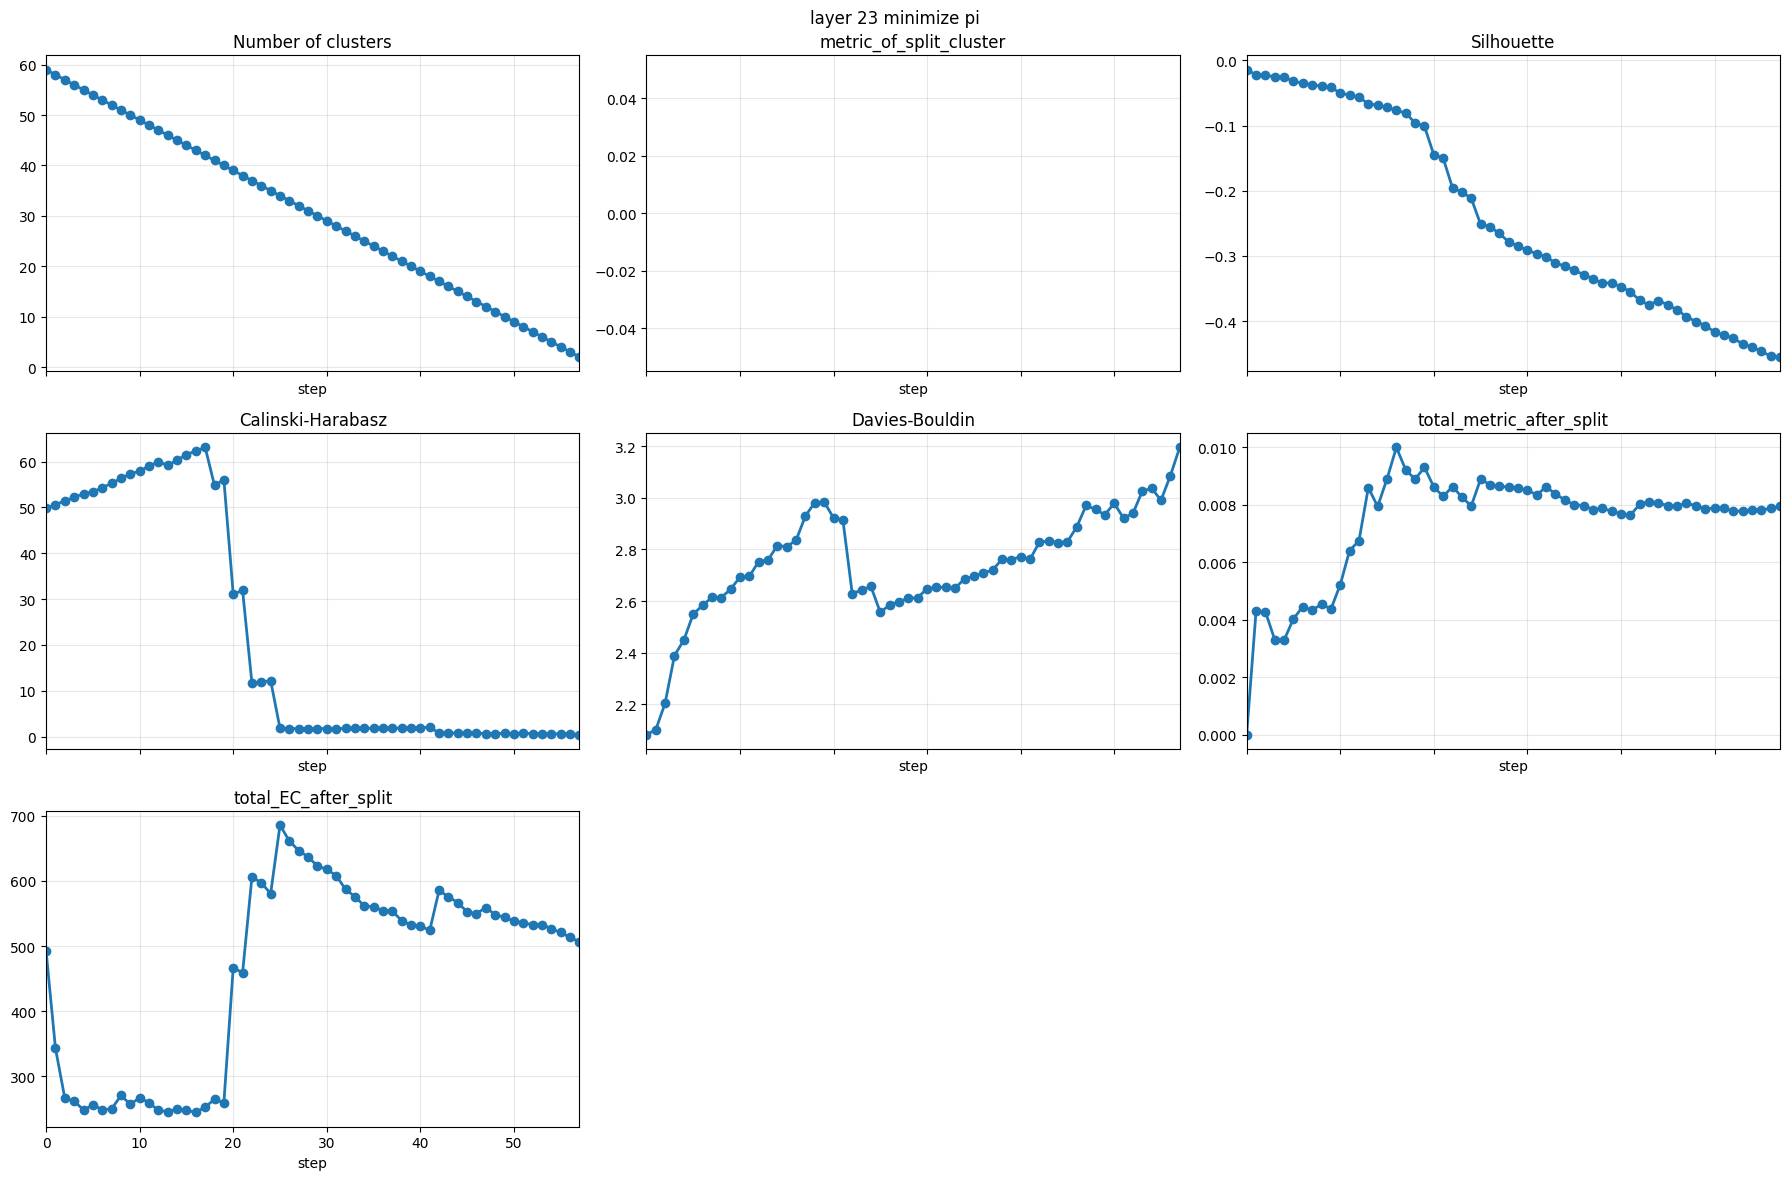

In [70]:
name2activations = clusterer._get_activations_from_gate([layers[23]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[23]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.gate.top_k)
clusters, history = find_by_agglomerative_clustering_2(gate_PI_matrix, 
                                                        maximize_metric=False, 
                                                        log_history=True,
                                                        other_matrices_for_stats={
                                                            'EC': gate_EC_matrix
                                                        })


layer_id = 23
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df = build_history_metrics_df(history, X_layer, row_experts)
history_df.tail(1)
plot_history_metrics(history_df, 'layer 23 minimize pi')

In [71]:
history_df

,step,n_clusters,metric_of_split_cluster,total_metric_after_split,total_EC_after_split,silhouette,calinski_harabasz,davies_bouldin
0,0,59,NaN,0.000000,492.000000,-0.014346,49.828420,2.082144
1,1,58,NaN,0.004292,343.142863,-0.022079,50.607625,2.100729
2,2,57,NaN,0.004277,266.404765,-0.023116,51.440643,2.204151
3,3,56,NaN,0.003303,262.092871,-0.024934,52.185365,2.388603
4,4,55,NaN,0.003291,248.317464,-0.025997,53.014779,2.448455
5,5,54,NaN,0.004033,255.993443,-0.031850,53.416978,2.549093
6,6,53,NaN,0.004452,248.856968,-0.035296,54.300732,2.583159
7,7,52,NaN,0.004323,249.852648,-0.037128,55.284141,2.614149
8,8,51,NaN,0.004544,270.596311,-0.039758,56.320352,2.613360
9,9,50,NaN,0.004364,256.964844,-0.041276,57.349071,2.646127


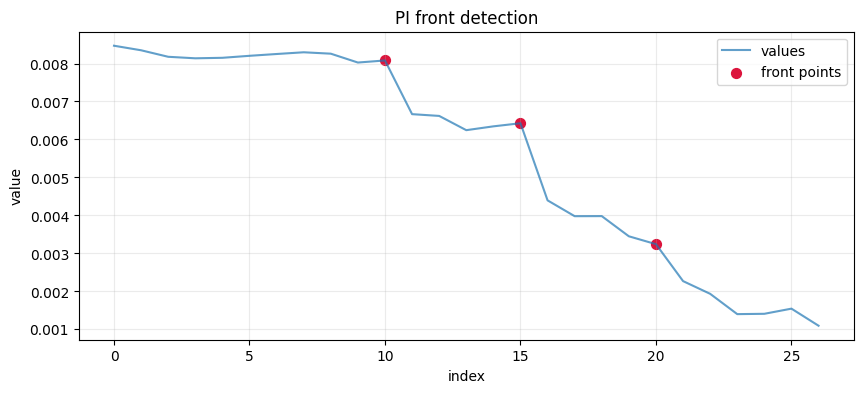

   idx     value  left_delta  right_delta  front_score  front_zscore
0   10  0.008080   -0.000113     0.001570     0.001457      1.495803
1   15  0.006428    0.000024     0.002308     0.002332      1.857874
2   20  0.003244   -0.000561     0.001374     0.000813      1.641503


In [99]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def detect_pi_front_points(
    values,
    skip_start=10,
    radius=3,
    neighborhood=3,
    z_threshold=1.0,
    min_curvature=0.0,
    require_local_peak=True,
):
    """Detect local front points on a curve.
    
    Args:
        values: numpy array or pandas Series of values
        skip_start: skip first N points
        radius: size of left/right window
        neighborhood: neighborhood size for local z-score
        z_threshold: z-score threshold for detection
        min_curvature: minimum front_score threshold
        require_local_peak: only accept local peaks
    
    Returns:
        DataFrame with detected front points (indices and scores)
    """
    values = np.asarray(values, dtype=np.float64)
    
    if values.size == 0:
        return pd.DataFrame()
    
    if values.size < max(skip_start + 2 * radius + 1, 2 * neighborhood + 1):
        return pd.DataFrame()

    front_score = np.full(len(values), np.nan, dtype=np.float64)
    left_delta = np.full(len(values), np.nan, dtype=np.float64)
    right_delta = np.full(len(values), np.nan, dtype=np.float64)

    start_idx = skip_start + radius
    stop_idx = len(values) - radius
    for idx in range(start_idx, stop_idx):
        left_window = values[idx - radius:idx]
        right_window = values[idx + 1:idx + 1 + radius]
        if left_window.size == 0 or right_window.size == 0:
            continue

        left_delta[idx] = values[idx] - left_window.mean()
        right_delta[idx] = values[idx] - right_window.mean()
        front_score[idx] = left_delta[idx] + right_delta[idx]

    score_series = pd.Series(front_score)
    local_mean = score_series.rolling(window=2 * neighborhood + 1, center=True, min_periods=1).mean()
    local_std = score_series.rolling(window=2 * neighborhood + 1, center=True, min_periods=1).std(ddof=0)
    score_z = (score_series - local_mean) / (local_std + 1e-12)

    if require_local_peak:
        local_max = score_series.rolling(window=2 * neighborhood + 1, center=True, min_periods=1).max()
        local_peak_mask = score_series.eq(local_max)
    else:
        local_peak_mask = pd.Series(True, index=score_series.index)

    candidate_mask = (
        np.arange(len(values)) >= start_idx
    ) & np.isfinite(front_score) & (front_score > min_curvature) & (score_z.to_numpy() > z_threshold) & local_peak_mask.fillna(False).to_numpy()

    indices = np.where(candidate_mask)[0]
    result = pd.DataFrame({
        'idx': indices,
        'value': values[indices],
        'left_delta': left_delta[indices],
        'right_delta': right_delta[indices],
        'front_score': front_score[indices],
        'front_zscore': score_z.to_numpy()[indices],
    })

    plt.figure(figsize=(10, 4))
    plt.plot(values, label="values", alpha=0.7)
    if len(result) > 0:
        plt.scatter(result['idx'], result['value'], color="crimson", s=50, label="front points")
    plt.title("PI front detection")
    plt.xlabel("index")
    plt.ylabel("value")
    plt.grid(True, alpha=0.25)
    plt.legend()
    plt.show()

    return result


# Usage example with one of the history dataframes
if 'history_df_23_max_EC' in dir():
    values_series = history_df_23_max_EC['total_PI_after_split'].to_numpy()
    front_points_pi = detect_pi_front_points(
        values_series,
        skip_start=5,
        radius=3,
        neighborhood=3,
        z_threshold=1.0,
        min_curvature=0.0,
        require_local_peak=True,
    )
    print(front_points_pi)


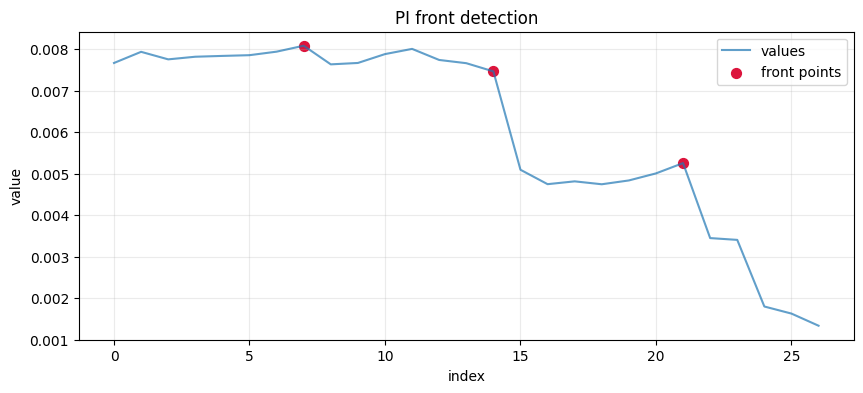

In [101]:
front_points_pi = detect_pi_front_points(
    history_df_0_max_ec['total_PI_after_split'],
    skip_start=5,
    radius=1,
    neighborhood=3,
    z_threshold=0.5,
    min_curvature=0.0,
    require_local_peak=True,
)

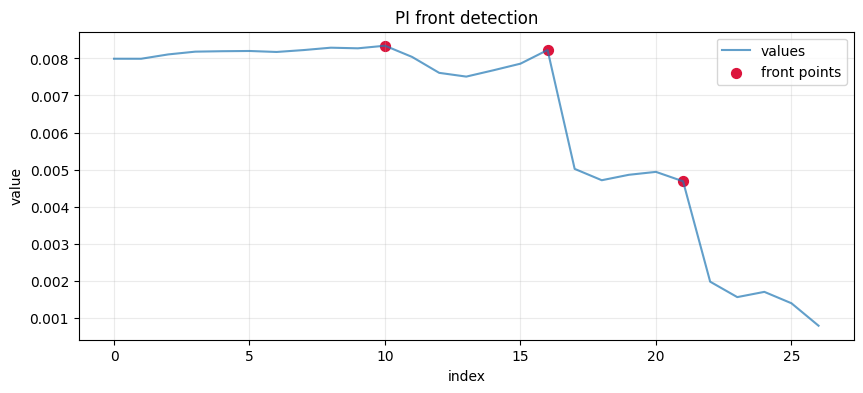

In [103]:
front_points_pi = detect_pi_front_points(
    history_df_11_max_ec['total_PI_after_split'],
    skip_start=5,
    radius=1,
    neighborhood=3,
    z_threshold=0.5,
    min_curvature=0.0,
    require_local_peak=True,
)

How it works for EC?? Bad

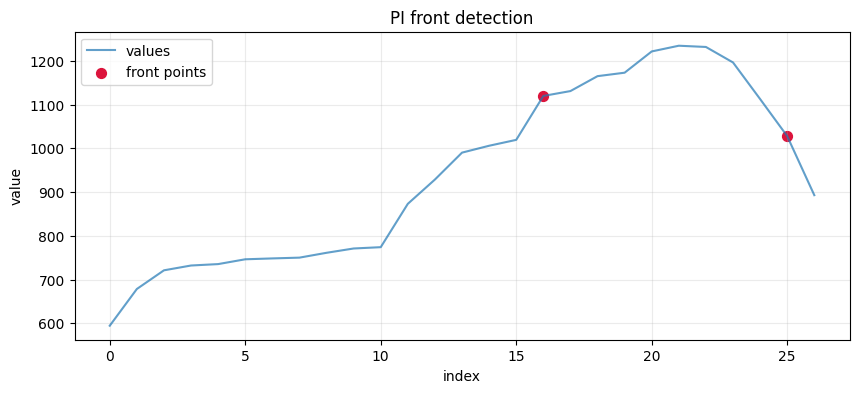

In [104]:
front_points_pi = detect_pi_front_points(
    history_df_23_max_EC['total_metric_after_split'],
    skip_start=5,
    radius=1,
    neighborhood=3,
    z_threshold=0.5,
    min_curvature=0.0,
    require_local_peak=True,
)

In [107]:
front_points_pi['idx'].to_list()

[16, 25]